In [1]:
from II_funcs import *
import corner
import re
plt.rcParams['mathtext.fontset'] =  "cm"
plt.rcParams['font.family'] =  "serif"
plt.rcParams['mathtext.default']='regular'

from IPython.display import FileLink
import gc
from scipy.interpolate import RectBivariateSpline
gc.collect()
theta_E_4 = np.array([np.sqrt(4 * G * .4*(2e33) / c**2 * D_ls / (D_s * D_l))])
theta_E_8 = np.array([np.sqrt(4 * G * .8*(2e33) / c**2 * D_ls / (D_s * D_l))])

data=np.load('macro_lens_results.npz')
mag_fit=6.86
phi_0=-2.07858699980682
B_matrix=data['inv_jacobian_fit'][0]
from scipy.interpolate import RegularGridInterpolator
from scipy.stats import linregress


D_s = 4.603e+27 cm
D_l = 3.085e+27 cm
D_ls = 3.708e+27 cm


In [2]:
def likelihood_static(params, inputs, num_stars, data_obs, sigma, sparse, ellipse_pts, pad_frac,
                      sampled=False, beta_min = 0.9e-11):
    """
    Returns the log-likelihood for given parameters. Handles null tests where num_stars = 0.
    Inputs:
        inputs:
            totalI_obs: measured intensity (sum)
            box_size: old, we don't use this anymore
            theta: array we'll warp to make beta
            intensity_fun: intensity function we will use to make our image from beta grid
    params: pertrubed parameters we're attempting to constrain (r_s, m_l, x, y)
        r_s in mas
        m_l in solar masses
        x,y in mas
    num_stars: 0 or 1 for us right now
    data_obs: correlation function values sampled at ellipse_pts
    sigma: error on correlation values
    sparse: always on at this point
    pad_frac: how much we pad our image when we pass it to uv space 
    sampled: old, always False at this point
    beta_min: I never touch this param anymore, cuttoff for beta when we do sparse image creation
    
    """
    #this is old, sampled is always False for us, I probably should remove this functionality at some point
    if sampled:
         uv_tracks,totalI_obs, box_size, theta, intensity_fun, theta_max, Ds, D_l,DLS, g_params = inputs
    else:
        totalI_obs, box_size, theta, intensity_fun, theta_max, Ds, D_l , DLS, g_params =inputs
    
    source_rad, m_stars, xpos, ypos = params
    theta_step = 2 * theta_max / len(theta[0])
    
    # Handle null case
    if num_stars == 0:
        m_stars = jnp.array([])  # Empty array for null test
        xpos = jnp.array([])
        ypos = jnp.array([])

    # Ensure arrays are valid
    source_rad=source_rad/rad_to_arcsec #given in mas, convert to radians
    m_stars = jnp.array(m_stars)
    
    #xpos =  (jnp.round(jnp.array(xpos)/(theta_step*rad_to_arcsec)).astype(int))#given in mas, convert to radians then pixels
    #ypos = (jnp.round(jnp.array(ypos)/(theta_step*rad_to_arcsec)).astype(int))
    xpos=jnp.array(xpos)/(rad_to_arcsec) #given in mas, convert to radians, above was for a pixelated earlier code version
    ypos =jnp.array(ypos)/(rad_to_arcsec)

    # Create star parameters
    arr_rand_idx = jnp.array((xpos, ypos)).T if len(xpos) > 0 else np.empty((0, 2))
    star_params = (m_stars, Ds, D_l, DLS, theta_max, (arr_rand_idx))
    
    if sparse:
        _, beta_sparse =beta(g_params, star_params, arr_theta)
        image, (indicesx, indicesy), vals = sparse_quasar_image(beta_sparse, source_rad, theta_max, beta_min, quasar_int_sparse)
        theta_step=2*theta_max/beta_sparse.shape[-1]
        _,_, model_values  = calcC_sparse(pad_image(image, int(beta_sparse.shape[-1]*pad_frac)), theta_step, 
                                     box_size=box_size, ellipse=False) #get full correlation, sample later

    else: #rarely are we using this part
        _, image, _, _ = increase_res(intensity_fun, source_rad, g_params, star_params, theta,)
        theta_step_hr = 2 * theta_max / len(image[0])
        theta_step= 2 * theta_max / len(image[0])

        model_values = calcC(pad_image(image, len(image[0])*pad_frac), theta_step_hr,
                              box_size=box_size, center_ind=center_ind, ellipse=False)
   
    #totalI_complex = jnp.sum(image.data.astype(jnp.complex128))  # complex, used for mag term only
    model_values=model_values[ellipse_pts[0], ellipse_pts[1]]  #sample the same as we on 'observed' data
   
    
    #magnification=(totalI_complex/totalI_obs)-1 
    #mag_error = 0.101  # fractional flux uncertainty from 0.11 mag
    #mag_term = -0.5 * ((magnification) / mag_error)**2 

    residuals = (model_values - data_obs)**2 / sigma**2
    II_term = -0.5 * jnp.sum(jnp.abs(residuals))
    log_likelihood = II_term  #+ mag_term
    return jnp.real(log_likelihood), jnp.real(II_term)#, jnp.real(mag_term)

def fisher_three_pt(params, inputs, num_stars, data_obs, sigma, delta, ll_func, elps_pts, pad_frac=10, sparse=False, 
           sampled=False):
    """
    Calculate the Fisher information matrix.
    Handles 0 to infinity stars by dynamically adjusting parameters.
    This is my old function which uses only the three point central difference to get the 2nd derivative. 
    
    This is also pretty slow on Jax because of how I copy the parameters, but it is the most stable when used with the discrete 
    alpha function I was using before with the II term
    Inputs:
        inputs:
            totalI_obs: measured intensity (sum)
            box_size: old, we don't use this anymore
            theta: array we'll warp to make beta
            intensity_fun: intensity function we will use to make our image from beta grid
    params: un-perturbed parameters we used to make data_obs 
        r_s in mas
        m_l in solar masses
        x,y in mas
    delta: how much we perturb each parameter by
    """
    
    totalI_obs, box_size, theta, intensity_fun, theta_max, Ds, D_l , DLS,  g_params =inputs
    theta_step = 2 * theta_max / len(theta[0])
    
    # Ensure `params` has the correct structure
    if num_stars == 0:
        params = [params[0], [], [], []]  # Add empty lists for m_stars, xpos, ypos

    # Flatten parameters for iteration
    source_rad, m_stars, xpos, ypos = params
    flat_params = [source_rad] + list(m_stars) + list(xpos) + list(ypos)
    
    # Adjust delta structure
    # just using one delta for both in this version of the code, might need to change that if we go back to these lower
    # order derivatives
    delta = [delta[0]] + delta[1:] * num_stars
    n_params = len(flat_params)
    
    fisher_full = np.zeros((n_params, n_params))
    fisher_II = np.zeros((n_params, n_params))
    fisher_mag = np.zeros((n_params, n_params))
    
    # Iterate over parameter pDLS,airs
    for i in range(n_params):
        for j in range(i, n_params):
            # Perturb parameters
            dtheta_i = delta[i]
            dtheta_j = delta[j]

            # Deep copy of parameters
            params_pp = copy.deepcopy(flat_params)
            params_pm = copy.deepcopy(flat_params)
            params_mp = copy.deepcopy(flat_params)
            params_mm = copy.deepcopy(flat_params)

            # Add perturbations
            params_pp[i] += dtheta_i
            params_pm[i] += dtheta_i
            params_mp[i] -= dtheta_i
            params_mm[i] -= dtheta_i

            params_pp[j] += dtheta_j
            params_pm[j] -= dtheta_j
            params_mp[j] += dtheta_j
            params_mm[j] -= dtheta_j
            
            def rebuild_params(flat):
                source_rad = flat[0]
                m_stars = flat[1:num_stars + 1]
                xpos = flat[num_stars + 1:2 * num_stars + 1]
                ypos = flat[2 * num_stars + 1:]
                return [source_rad, m_stars, xpos, ypos]

            params_pp = rebuild_params(params_pp)
            params_pm = rebuild_params(params_pm)
            params_mp = rebuild_params(params_mp)
            params_mm = rebuild_params(params_mm)
            
            ll_pp, II_pp= ll_func(params_pp, inputs, num_stars, data_obs, sigma, sparse, elps_pts, pad_frac, sampled)
            ll_pm, II_pm = ll_func(params_pm, inputs, num_stars, data_obs, sigma, sparse, elps_pts, pad_frac, sampled)
            ll_mp, II_mp= ll_func(params_mp, inputs, num_stars, data_obs, sigma, sparse, elps_pts, pad_frac, sampled)
            ll_mm, II_mm = ll_func(params_mm, inputs, num_stars, data_obs, sigma, sparse, elps_pts, pad_frac, sampled)            
            
            # Compute second derivatives for each term
            def second_deriv(a_pp, a_pm, a_mp, a_mm):
                return (a_pp - a_pm - a_mp + a_mm) / (4 * dtheta_i * dtheta_j)

            #store the negative of each derivative
            fisher_full[i, j] = -jnp.sum(second_deriv(ll_pp, ll_pm, ll_mp, ll_mm))
            fisher_II[i, j] = -jnp.sum(second_deriv(II_pp, II_pm, II_mp, II_mm))
            #fisher_mag[i, j] = -jnp.sum(second_deriv(mag_pp, mag_pm, mag_mp, mag_mm))
            
            # Symmetrize
            fisher_full[j, i] = fisher_full[i, j]
            fisher_II[j, i] = fisher_II[i, j]
            #fisher_mag[j, i] = fisher_mag[i, j]

    return fisher_full, fisher_II#, fisher_mag


In [3]:
#define image specific constants, these don't change within this file
theta_max = 2e-10 # (half) size of image
image_size=8000
N_step = image_size
beta_min = .9e-11
rad = theta_500  
rad_mas=rad*rad_to_arcsec
g_params = (kappa_bulk, gamma1, gamma2)
sigma_C = error_C(mag=16.5, wavelength=500*1e-7, R = 2e4, sigma_t=3e-12, A=10*(500**2)*np.pi, t_obs= 8 * 3600)

In [4]:
def rotate_data_pos(xpts, ypts, theta):
    "xpts, ypts are relative to 0 0 in the right bottom corner of the image. theta in radians"
    xpts=np.array(xpts)
    ypts=np.array(ypts)
    xpts=xpts-0.5
    ypts=ypts-0.5
    rs=np.sqrt(xpts**2+ypts**2)
    x2=rs*np.cos(np.arctan2(xpts, ypts)+theta)
    y2=rs*np.sin(np.arctan2(xpts, ypts)+theta)
    return x2, y2

def load_file(file, skip_lines=0, matrix=True, force_shape=(4,4)):
    """
    Parse file with entries where each entry has a header (5 or 6 numeric tokens)
    followed by a matrix block between [[ and ]].
    Returns:
      out_xval: (N,2) array (second column nan if header had single x)
      out_rad, out_mass, out_x, out_y: 1D arrays length N
      out_mat: list of numpy arrays (each either reshaped to force_shape if possible, else 1D)
    """
    # token regex matches floats (with optional exp), ints, or 'nan'
    token_re = re.compile(r'[-+]?\d*\.\d+(?:[eE][-+]?\d+)?|[-+]?\d+|nan', flags=re.I)
    with open(file, 'r') as fh:
        lines = fh.readlines()[skip_lines:]
    raw = "".join(lines)

    out_x1, out_x2 = [], []
    out_rad, out_mass, out_x, out_y = [], [], [], []
    out_mat = []

    # find all matrix blocks; iterate in order and take header as text since previous end
    prev_end = 0
    for m in re.finditer(r'\[\[.*?\]\]', raw, flags=re.S):
        header_text = raw[prev_end:m.start()].strip()
        matrix_text = m.group()
        prev_end = m.end()

        # extract numeric-ish tokens from header (includes 'nan')
        header_tokens = token_re.findall(header_text)
        if not header_tokens:
            raise ValueError(f"No numeric tokens found in header preceding matrix at pos {m.start()}")

        # convert tokens to floats, treating 'nan' correctly
        def tok_to_float(t):
            return np.nan if t.lower() == 'nan' else float(t)
        header_vals = [tok_to_float(t) for t in header_tokens]

        # map header tokens -> fields (6-token or 5-token)
        if len(header_vals) == 6:
            x1, x2, rad, mass, xpos, ypos = header_vals
        elif len(header_vals) == 5:
            x1, x2 = header_vals[0], np.nan
            rad, mass, xpos, ypos = header_vals[1], header_vals[2], header_vals[3], header_vals[4]
        else:
            raise ValueError(
                f"Unexpected number of header tokens ({len(header_vals)}) found: {header_tokens!r}\n"
                "Expected 5 or 6 tokens."
            )

        out_x1.append(x1)
        out_x2.append(x2)
        out_rad.append(rad)
        out_mass.append(mass)
        out_x.append(xpos)
        out_y.append(ypos)

        if matrix:
            mat_tokens = token_re.findall(matrix_text)
            if not mat_tokens:
                mat_arr = np.array([], dtype=float)
            else:
                mat_vals = [tok_to_float(t) for t in mat_tokens]
                mat_arr = np.array(mat_vals, dtype=float)
                # reshape if shape matches force_shape
                if force_shape is not None and mat_arr.size == np.prod(force_shape):
                    mat_arr = mat_arr.reshape(force_shape)
            out_mat.append(mat_arr)

    # if there was trailing text after last matrix containing another valid entry without matrix,
    # it won't be processed. That's intentional: function associates matrices with preceding headers.

    out_xval = np.column_stack([np.array(out_x1, dtype=float), np.array(out_x2, dtype=float)])
    return (out_xval,
            np.array(out_rad, dtype=float),
            np.array(out_mass, dtype=float),
            np.array(out_x, dtype=float),
            np.array(out_y, dtype=float),
            out_mat if matrix else None)
    
def load_mag_file(file, skip_lines=0, matrix=True, force_shape=(4,4)):
    """
    Parse file with entries where each entry has a header (5 or 6 numeric tokens)
    followed by a matrix block between [[ and ]].
    Returns:
      out_xval: (N,2) array (second column nan if header had single x)
      out_rad, out_mass, out_x, out_y: 1D arrays length N
      out_mat: list of numpy arrays (each either reshaped to force_shape if possible, else 1D)
    """
    # token regex matches floats (with optional exp), ints, or 'nan'
    token_re = re.compile(r'[-+]?\d*\.\d+(?:[eE][-+]?\d+)?|[-+]?\d+|nan', flags=re.I)
    with open(file, 'r') as fh:
        lines = fh.readlines()[skip_lines:]
    raw = "".join(lines)

    out_x1, out_x2 = [], []
    out_mat = []

    # find all matrix blocks; iterate in order and take header as text since previous end
    prev_end = 0
    for m in re.finditer(r'\[\[.*?\]\]', raw, flags=re.S):
        header_text = raw[prev_end:m.start()].strip()
        matrix_text = m.group()
        prev_end = m.end()

        # extract numeric-ish tokens from header (includes 'nan')
        header_tokens = token_re.findall(header_text)
        if not header_tokens:
            raise ValueError(f"No numeric tokens found in header preceding matrix at pos {m.start()}")

        # convert tokens to floats, treating 'nan' correctly
        def tok_to_float(t):
            return np.nan if t.lower() == 'nan' else float(t)
        header_vals = [tok_to_float(t) for t in header_tokens]

        # map header tokens -> fields (6-token or 5-token)
        if len(header_vals) == 2:
            x1, x2 = header_vals
        if len(header_vals) == 1:
            x1 = header_vals
            x2=0
        #elif len(header_vals) == 5:
        #    x1, x2 = header_vals[0], np.nan
        #    rad, mass, xpos, ypos = header_vals[1], header_vals[2], header_vals[3], header_vals[4]
        #else:
        #    raise ValueError(
        #        f"Unexpected number of header tokens ({len(header_vals)}) found: {header_tokens!r}\n"
        #        "Expected 5 or 6 tokens."
        #    )

        out_x1.append(x1)
        out_x2.append(x2)

        if matrix:
            mat_tokens = token_re.findall(matrix_text)
            if not mat_tokens:
                mat_arr = np.array([], dtype=float)
            else:
                mat_vals = [tok_to_float(t) for t in mat_tokens]
                mat_arr = np.array(mat_vals, dtype=float)
                # reshape if shape matches force_shape
                if force_shape is not None and mat_arr.size == np.prod(force_shape):
                    mat_arr = mat_arr.reshape(force_shape)
            out_mat.append(mat_arr)

    # if there was trailing text after last matrix containing another valid entry without matrix,
    # it won't be processed. That's intentional: function associates matrices with preceding headers.
    if np.array(out_x2).any!=0:
        out_xval = np.column_stack([np.array(out_x1, dtype=float), np.array(out_x2, dtype=float)])
    else:
        out_xval = np.column_stack([np.array(out_x1, dtype=float)])
    return (out_xval,
            out_mat if matrix else None)

def load_cents(file):
    centroids=[]
    positions=[]
    with open(file, 'r') as fh:
        lines = fh.readlines()[:]
        for i in range(len(lines)):
            
            positions.append(np.array((float(lines[i].split(']')[0].split('[')[1].split(' ')[0]), 
                                       float(lines[i].split(']')[0].split('[')[1].split(' ')[1]))))
            J0=(np.array((float((lines[i].split(']')[1].split('[[')[1]).split(',')[0]), 
                                           float((lines[i].split(']')[1].split('[[')[1]).split(',')[1]))))
            J1=(np.array((float((lines[i].split(']')[3].split('[[')[1]).split(',')[0]), 
                                           float((lines[i].split(']')[3].split('[[')[1]).split(',')[1]))))
            J2=(np.array((float((lines[i].split(']')[5].split('[[')[1]).split(',')[0]), 
                                           float((lines[i].split(']')[5].split('[[')[1]).split(',')[1]))))
            J3=(np.array((float((lines[i].split(']')[7].split('[[')[1]).split(',')[0]), 
                                           float((lines[i].split(']')[7].split('[[')[1]).split(',')[1]))))

            J_cent=np.vstack([J0, J1, J2, J3]).T
            centroids.append(J_cent)

    return (np.array(positions), np.array(centroids))
    

def get_combo_cov(fisher_mag, cov_II, theta_step_mag, theta_step_II, numstars):
    # Convert cov_II to Fisher
    fisher_II = jnp.linalg.inv(cov_II.reshape(1+3*numstars, 1+3*numstars))

    # Rescale both to radians
    fisher_mag_rescaled = rescale_fisher_to_radians(fisher_mag, theta_step_mag, numstars)
    fisher_II_rescaled  = rescale_fisher_to_radians(fisher_II, theta_step_II, numstars)

    # Combine
    fisher_tot = fisher_mag_rescaled + fisher_II_rescaled

    # Final covariance + uncertainties (now in radians)
    cov_tot, uncertainties_tot = parameter_uncertainties(
        fisher_tot,
        theta_step=1.0,   # already in radians, no further scaling
        printout=False,
        numstars=numstars
    )

    return cov_tot, uncertainties_tot

def rescale_fisher_to_radians(F, theta_step, numstars):
    n_params = 1 + 3*numstars
    J = jnp.eye(n_params)

    # indices
    x_start = 1 + numstars
    y_start = 1 + 2*numstars

    # scale x and y
    J = J.at[x_start:x_start+numstars, x_start:x_start+numstars].set(theta_step)
    J = J.at[y_start:y_start+numstars, y_start:y_start+numstars].set(theta_step)

    # transform Fisher matrix
    return J.T @ F @ J

def load_chi2s(file, skip_lines=0):
    """
    get chi2s from file
    """
    # token regex matches floats (with optional exp), ints, or 'nan'
    token_re = re.compile(r'[-+]?\d*\.\d+(?:[eE][-+]?\d+)?|[-+]?\d+|nan', flags=re.I)
    with open(file, 'r') as fh:
        lines = fh.readlines()[skip_lines:]
    raw = "".join(lines)
    out_chis = []
    for line in lines:
        header_tokens = token_re.findall(line)
        if not header_tokens:
            raise ValueError(f"No numeric tokens found in header preceding matrix at pos {m.start()}")
        if len(header_tokens) == 3:
            x1, x2, chi = header_tokens        
        out_chis.append(chi)
    return np.array(out_chis, dtype=float)

def get_velocities(v_rest, B_matrix, redshift, lens_dist):
    """
    Inputs
        v_rest: velocity of the star in the lens plane in the same units at lens_dist/unit time
        redshift: redshift of lens (star)
        lens_dist: angular diameter distance to lens
        B_matrix: macrolensing matrix, inv_jacobian_fit
    Returns the lensed proper motion of the star in radians 
    """
    mu_rest = v_rest /(1 + redshift) * (1 / lens_dist) 
    mu_x = mu_rest[0] * B_matrix[0, 0] + mu_rest[1] * B_matrix[0, 1]
    mu_y = mu_rest[0] * B_matrix[1, 0] + mu_rest[1] * B_matrix[1, 1]
    return np.array((mu_x, mu_y))
    
def rescale_cov_to_radians(C, theta_step, numstars):
    n_params = 1 + 3*numstars
    J = jnp.eye(n_params)

    # indices
    x_start = 1 + numstars
    y_start = 1 + 2*numstars

    # scale x and y
    J = J.at[x_start:x_start+numstars, x_start:x_start+numstars].set(theta_step)
    J = J.at[y_start:y_start+numstars, y_start:y_start+numstars].set(theta_step)

    return J @ C @ J.T


def sim_rand_traj(bulk_vel, bulk_vel_err, vel_disp, vel_disp_err, theta_max, N, redshift, lens_dist, B_matrix, dist, 
                  dt_days=182.0, max_time_days= 5 * 365.0):
    """
    Simulate a single star trajectory in radians on an image grid
    Returns dict {'times_days', 'positions_rad' (radians Nx2), 'pixel_indices' (Nx2 ints), 'initial_position_rad', 'velocity_kms}

    Inputs:
        bulk_vel: km/s, asusmed to be entirely in the x direction (arb)
        bulk_vel_err: km/s
        vel_disp: km/s, velocity dispersion of the lensing galaxy
        theta_max: image smapens -theta_max to theta_max in x and y, radians
        N: number of pixels
        redshift: redshift of star
        lens_dist: in cm 
        B_matrix: inv_jacobian of the macrolensing stuff
        dt_days: cadence in days
        max_time_days: safety if we get a slow star     
    Returns:
        times_Deays: 1D array
        positions_rad: Nx2 array in rad
        pixel_indices: Nx2, ints, -1 for outside image
    The star passes at closest approach (impact parameter) = dist at t = 0.
    We integrate forward and backward in time with cadence dt_days.

    """

    km_to_cm = 1e5
    day_to_sec = 86400.0
    dt_sec = dt_days * day_to_sec
    max_time_sec = max_time_days * day_to_sec

    total_span = 2.0 * theta_max
    pixel_size = total_span / N

    # vel in km/s
    tot_vel=np.sqrt(bulk_vel**2+vel_disp**2)
    vel_angle=np.random.uniform(0, 2 * np.pi)
    
    v_x_kms =np.cos(vel_angle)*tot_vel #(np.random.normal(loc=bulk_vel, scale=bulk_vel_err)
               #+ np.random.normal(loc=0, scale=np.sqrt(vel_disp**2 + vel_disp_err**2)))
    v_y_kms = np.sin(vel_angle)*tot_vel#np.random.normal(loc=0, scale=np.sqrt(vel_disp**2 + vel_disp_err**2))

    # to angular
    v_rest = np.array([v_x_kms, v_y_kms]) * km_to_cm #to match lens_dist units
    v_ang = get_velocities(v_rest, B_matrix, redshift, lens_dist)
    v_x_ang, v_y_ang = v_ang

    v_norm = np.hypot(v_x_ang, v_y_ang)
    if v_norm == 0:
        raise ValueError("Zero velocity — cannot define trajectory direction.")

    # position at closest approach
    # direction perpendicular to velocity vector
    #phi = np.random.uniform(0, 2 * np.pi)  # pick random orientation of velocity
    # rotate velocity vector by angle phi around center to randomize orientation
    # rot = np.array([[np.cos(phi), -np.sin(phi)], [np.sin(phi), np.cos(phi)]])
    #v_ang_rot = rot @ np.array([v_x_ang, v_y_ang])
    #v_x_ang, v_y_ang = v_ang_rot

    # perpendicular unit vector
    n_perp = np.array([-v_y_ang, v_x_ang]) / np.hypot(v_x_ang, v_y_ang)
    theta0 = dist * n_perp  # position at closest approach
    theta_x0, theta_y0 = theta0
    times = np.arange(-max_time_sec, max_time_sec + dt_sec, dt_sec)

    theta_x = theta_x0 + v_x_ang * times
    theta_y = theta_y0 + v_y_ang * times
    positions = np.column_stack([theta_x, theta_y])
    pix_x = np.floor((theta_x + theta_max) / pixel_size).astype(int)
    pix_y = np.floor((theta_y + theta_max) / pixel_size).astype(int)
    
    inside = (pix_x >= 0) & (pix_x < N) & (pix_y >= 0) & (pix_y < N)
    
    """
    if not np.all(inside):
        first_out = np.argmax(~inside)   # first False
        # truncate arrays
        times = times[:first_out]
        theta_x = theta_x[:first_out]
        theta_y = theta_y[:first_out]
        pix_x = pix_x[:first_out]
        pix_y = pix_y[:first_out]
    """
    
    outside_mask = (pix_x < 0) | (pix_x >= N) | (pix_y < 0) | (pix_y >= N)
    pix_x[outside_mask] = -1
    pix_y[outside_mask] = -1
    pixel_indices = np.column_stack([pix_x, pix_y])

    times_days = times / day_to_sec

    return {"times_days": times_days, "positions_rad": positions, "pixel_indices": pixel_indices,
        "closest_approach_rad": (theta_x0, theta_y0), "velocity_kms": (v_x_kms, v_y_kms),
        "proper_motion": (v_x_ang, v_y_ang)} # rad/s


In [5]:
theta_step = 2 * (2e-10) / 8000
theta_step_mag = 2 * (1.5e-10) / 8000

Load in the data over the position grids for both masses

In [6]:
position_04_mag, fish_04_mag = load_mag_file('m04_78tE_mag.txt')#, nval_x=2)
position_04, rad_04, mass_04, xpos_04, ypos_04, cov_04 = load_file('m04_78tE_II.txt')#, nval_x=3)

cov_combo_04 = []
rad_04_combo = []
mass_04_combo = []
posx_04_combo = []
posy_04_combo = []

for i in range(len(fish_04_mag)):
    mag_fisher=rescale_fisher_to_radians(fish_04_mag[i], theta_step_mag, 1)
    cov_fisher=rescale_cov_to_radians(cov_04[i], theta_step, 1)
    combo_cov, sigma_combo=get_combo_cov(mag_fisher, cov_fisher, theta_step_mag, theta_step, 1)
    cov_combo_04.append(combo_cov)
    rad_04_combo.append(sigma_combo[0])
    mass_04_combo.append(sigma_combo[1])
    posx_04_combo.append(sigma_combo[2])
    posy_04_combo.append(sigma_combo[3])

rad_04_combo=np.array(rad_04_combo)#/(theta_500*rad_to_arcsec)
mass_04_combo=np.array(mass_04_combo)
posx_04_combo=np.array(posx_04_combo)
posy_04_combo=np.array(posy_04_combo)

position_04_rad=position_04/8000#*theta_step
angle_rot=(-phi_0+np.pi/2)
x_rot, y_rot = rotate_data_pos(position_04_rad.T[0], position_04_rad.T[1], angle_rot)
positions_rot = np.stack([(-np.abs(x_rot)).flatten(), (np.abs(y_rot)).flatten()], axis=1) * theta_step * image_size
#rotated_img=rotate(np.asarray(image_0.todense()),angle_rot*(360/(2*np.pi)))

In [7]:
chis_04_mag = load_chi2s('m04_78tE_chi2_mag.txt')#, nval_x=2)
chis_04_II = load_chi2s('m04_78tE_chi2_II.txt')#, nval_x=2)
chi_combo_04=chis_04_II+chis_04_mag
pos_cent, centroids= load_cents('m04_78tE_cent.txt') #centroids is a misnomer, its the jacobian of the centroids
centroids=centroids.reshape(12,12,2,4)

In [8]:
Sigma_cent= np.einsum('...ia,...ab,...jb->...ij',  centroids*rad_to_arcsec, np.array(cov_combo_04).reshape(12,12,4,4), centroids*rad_to_arcsec)

sigma_x_tot = np.sqrt(Sigma_cent[:,:,0, 0])#*rad_to_arcsec
sigma_y_tot = np.sqrt(np.abs(Sigma_cent[:,:,1, 1]))#*rad_to_arcsec
cent_pres=np.sqrt(sigma_y_tot**2+sigma_x_tot**2)
sigma_c1=np.linalg.det(Sigma_cent).ravel()
sigma_c2=np.min(np.linalg.eigvals(Sigma_cent.reshape(144,2,2)), axis=1)

In [9]:
bulk_vel=400
bulk_vel_err=100
vel_disp=178
vel_disp_err=35

dist_x = get_velocities(np.array([0, np.sqrt(bulk_vel**2+vel_disp**2)*1e5]), B_matrix, z_l, D_l)
mu_x=np.sqrt(dist_x[0]**2+dist_x[1]**2)*356*24*3600*rad_to_arcsec


### Interpolate errors

In [10]:
n = int(np.sqrt(len(x_rot)))

x_grid = np.unique(positions_rot[:, 0].round(decimals=15))#*theta_step * image_size
x_grid = np.concat((x_grid, (-x_grid[len(x_grid)-2::-1])))
y_grid = np.unique(positions_rot[:, 1].round(decimals=15))#*theta_step * image_size
y_grid = np.concat((-y_grid[::-1], (y_grid[1:])))

rad_grid  = rad_04_combo.reshape(n, n)
mass_grid = mass_04_combo.reshape(n, n)
xpos_grid = posx_04_combo.reshape(n, n)
ypos_grid = posy_04_combo.reshape(n, n)


In [11]:
n

12

In [12]:
len(x_grid)

23

In [13]:
def one_quad_to_full(quad_arr, n):
    arr_quadrant = quad_arr.reshape(n, n)  # this is for x<0, y<0
    
    y_reflect = np.flipud(arr_quadrant)
    x_reflect = np.fliplr(arr_quadrant)
    xy_reflect = np.flipud(np.fliplr(arr_quadrant))
    
    right = np.concatenate((xy_reflect, y_reflect[:, 1:]), axis=1)
    left = np.concatenate((np.fliplr(arr_quadrant), np.fliplr(x_reflect)[:, 1:]), axis=1)
    
    return np.concatenate((right[:-1, :], left), axis=0)

In [14]:
rad_grid  = one_quad_to_full(rad_04_combo, n)
mass_grid = one_quad_to_full(mass_04_combo, n)
xpos_grid = one_quad_to_full(posx_04_combo, n)
ypos_grid = one_quad_to_full(posy_04_combo, n)


In [15]:
# Build interpolators
rad_spline  = RegularGridInterpolator([x_grid, y_grid], rad_grid, method='linear')
mass_spline = RegularGridInterpolator([x_grid, y_grid], mass_grid, method='linear')
xpos_spline = RegularGridInterpolator([x_grid, y_grid], xpos_grid, method='linear') #takes position in radians, returns in mas
ypos_spline = RegularGridInterpolator([x_grid, y_grid], ypos_grid, method='linear')

In [16]:
fine_grid_x=np.linspace(np.min(x_grid), np.max(x_grid), 200)
fine_grid_y=np.linspace(np.min(y_grid), np.max(y_grid), 200)
X_fine, Y_fine = np.meshgrid(fine_grid_x, fine_grid_y, indexing='ij')
#mass_interp = mass_spline.ev(X_fine.ravel(), Y_fine.ravel()).reshape(Y_fine.shape)

In [17]:
points = np.stack([X_fine.ravel(), Y_fine.ravel()], axis=-1)
rad_interp = rad_spline(points).reshape(X_fine.shape)
mass_interp = mass_spline(points).reshape(X_fine.shape)
xpos_interp = xpos_spline(points).reshape(X_fine.shape)
ypos_interp = ypos_spline(points).reshape(X_fine.shape)

### Interpolate fisher matricies for m=0.8

In [18]:
def matrix_to_full(quad_arr, n):
    arr_quadrant = quad_arr.reshape(n, n, 4, 4)  # this is for x<0, y<0
    
    y_reflect = np.flipud(arr_quadrant)
    x_reflect = np.fliplr(arr_quadrant)
    xy_reflect = np.flipud(np.fliplr(arr_quadrant))
    
    right = np.concatenate((xy_reflect, y_reflect[:, 1:]), axis=1)
    left = np.concatenate((np.fliplr(arr_quadrant), np.fliplr(x_reflect)[:, 1:]), axis=1)
    
    return np.concatenate((right[:-1, :], left), axis=0)

def Jac_to_full(quad_arr, n):
    # quad_arr shape: (n, n, 2, 4)
    arr = quad_arr.reshape(n, n, 2, 4)

    y_reflect  = np.flipud(arr)
    x_reflect  = np.fliplr(arr)
    xy_reflect = np.flipud(np.fliplr(arr))

    right = np.concatenate((xy_reflect, y_reflect[:, 1:]), axis=1)
    left  = np.concatenate((np.fliplr(arr), np.fliplr(x_reflect)[:, 1:]), axis=1)

    full = np.concatenate((right[:-1, :], left), axis=0)

    return full


In [19]:
f_combo_04=[]
for i in range(len(cov_combo_04)):
    f_combo_04.append(np.linalg.inv(cov_combo_04[i]))
f_combo_04=np.array(f_combo_04)
f_combo_04 = f_combo_04.reshape(n, n, 4, 4)
f_combo_04  = matrix_to_full(f_combo_04, n)

In [20]:
splines_f04 = [[RectBivariateSpline(x_grid, y_grid, f_combo_04[:, :, i, j])#, s=1e-24)
            for j in range(4)] for i in range(4)]
def fisher_spline(pos_arr):
    x=pos_arr[0]
    y=pos_arr[1]
    return np.array([[splines_f04[i][j](x, y)[0,0] for j in range(4)] for i in range(4)])

In [21]:
fine_grid_x=np.linspace(np.min(x_grid), np.max(x_grid), 400)
fine_grid_y=np.linspace(np.min(y_grid), np.max(y_grid), 400)
X_fine, Y_fine = np.meshgrid(fine_grid_x, fine_grid_y, indexing='ij')


In [22]:
Z_det=np.empty((len(fine_grid_x), len(fine_grid_y)))
for i, x in enumerate(fine_grid_x):
    for j, y in enumerate(fine_grid_y):
       
        f_original = fisher_spline([x, y])      
        Z_det[i, j] = np.linalg.det(f_original) 

In [23]:
interpolators = [[None for j in range(4)] for i in range(4)]

for i in range(4):
    for j in range(4):
        # Linear interpolation; 'bounds_error=False' allows extrapolation if needed
        interpolators[i][j] = RegularGridInterpolator(
            (x_grid, y_grid),
            f_combo_04[:, :, i, j], bounds_error=False, method='linear', fill_value=np.nan)
def fisher_interp_linear(pos):
    x, y = pos
    M = np.zeros((4, 4))
    for i in range(4):
        for j in range(4):
            M[i, j] = interpolators[i][j]([x, y])
    # enforce symmetry
    M = 0.5 * (M + M.T)
    return M
def fisher_interp_grid(pos):
    x, y = pos[:, 0], pos[:, 1]
    N = len(x)

    M = np.zeros((N, 4, 4))
    for i in range(4):
        for j in range(4):
            M[:, i, j] = interpolators[i][j](np.column_stack((x, y)))

    # enforce symmetry on the last two axes only
    M = 0.5 * (M + np.swapaxes(M, -1, -2))
    return M

In [24]:
fine_grid_x=np.linspace(np.min(x_grid), np.max(x_grid), 200)
fine_grid_y=np.linspace(np.min(y_grid), np.max(y_grid), 200)
X_fine, Y_fine = np.meshgrid(fine_grid_x, fine_grid_y, indexing='ij')
points = np.stack([X_fine.ravel(), Y_fine.ravel()], axis=-1)
Fvals_interp = fisher_interp_grid(points).reshape((200,200,4,4))


### Interpolate chi^2, centroids

In [25]:
chi_grid  = one_quad_to_full(chi_combo_04, n)

fine_grid_x=np.linspace(np.min(x_grid), np.max(x_grid), 200)
fine_grid_y=np.linspace(np.min(y_grid), np.max(y_grid), 200)
X_fine, Y_fine = np.meshgrid(fine_grid_x, fine_grid_y, indexing='ij')
points = np.stack([X_fine.ravel(), Y_fine.ravel()], axis=-1)

chi_spline  = RegularGridInterpolator([x_grid, y_grid], chi_grid, bounds_error=False, method='linear', fill_value=np.nan)
chi_interp  = chi_spline(points).reshape(X_fine.shape)

In [49]:
Jcent_grid

array([[[[ 6.94694327e-12, -7.25221333e-12, -2.55792692e-13,
           1.89809237e-13],
         [ 3.49170163e-12, -5.30725502e-12, -3.75669275e-13,
           1.25753402e-13]],

        [[ 8.42419902e-12, -7.14608011e-12,  7.10246020e-14,
           1.88470185e-13],
         [ 4.31811873e-12, -5.49554131e-12,  9.47630288e-13,
           1.34213099e-13]],

        [[ 9.92135844e-12, -6.83296899e-12, -3.05220880e-13,
           1.76778059e-13],
         [ 5.21502517e-12, -5.09771557e-12, -4.90752122e-13,
           1.22468049e-13]],

        ...,

        [[ 9.92135844e-12, -6.83296899e-12, -3.05220880e-13,
           1.76778059e-13],
         [ 5.21502517e-12, -5.09771557e-12, -4.90752122e-13,
           1.22468049e-13]],

        [[ 8.42419902e-12, -7.14608011e-12,  7.10246020e-14,
           1.88470185e-13],
         [ 4.31811873e-12, -5.49554131e-12,  9.47630288e-13,
           1.34213099e-13]],

        [[ 6.94694327e-12, -7.25221333e-12, -2.55792692e-13,
           1.89809237e-13

In [28]:

centroids=centroids.reshape(n,n,2,4)
Jcent_grid  = Jac_to_full(centroids, n)

interpolators_cent=[[None for i in range(4)] for a in range(2)]

for a in range(2):        # centroid x/y
    for i in range(4):    # parameters
        interpolators_cent[a][i] = RegularGridInterpolator(
        (x_grid, y_grid),
        Jcent_grid[:, :, a, i], bounds_error=False, method='linear', fill_value=np.nan)

def Jcent_interp(pos):
    x, y = pos
    J = np.zeros((2, 4))
    for a in range(2):
        for i in range(4):
            J[a, i] = interpolators_cent[a][i]([x, y])
    return J

cent_pres  = one_quad_to_full(cent_pres, n)
cent_spline = RegularGridInterpolator([x_grid, y_grid], cent_pres, method='linear', fill_value=np.nan)
cent_interp = cent_spline(points).reshape(X_fine.shape)

sigma_c1  = one_quad_to_full(sigma_c1, n)
sigma_c1_spline = RegularGridInterpolator([x_grid, y_grid], sigma_c1, method='linear', fill_value=np.nan)
sigma_c1_interp = sigma_c1_spline(points).reshape(X_fine.shape)

sigma_c2  = one_quad_to_full(sigma_c2, n)
sigma_c2_spline = RegularGridInterpolator([x_grid, y_grid], sigma_c2, method='linear', fill_value=np.nan)
sigma_c2_interp = sigma_c2_spline(points).reshape(X_fine.shape)

ValueError: cannot reshape array of size 529 into shape (12,12)

In [30]:
chi_grid_II  = one_quad_to_full(chis_04_II, n)
chi_spline_II  = RegularGridInterpolator([x_grid, y_grid], chi_grid_II, bounds_error=False, method='linear', fill_value=np.nan)

chi_grid_mag  = one_quad_to_full(chis_04_mag, n)
chi_spline_mag  = RegularGridInterpolator([x_grid, y_grid], chi_grid_mag, bounds_error=False, method='linear', fill_value=np.nan)

/mnt/home/amoran/lensing/M04/Figures/chi04.pdf

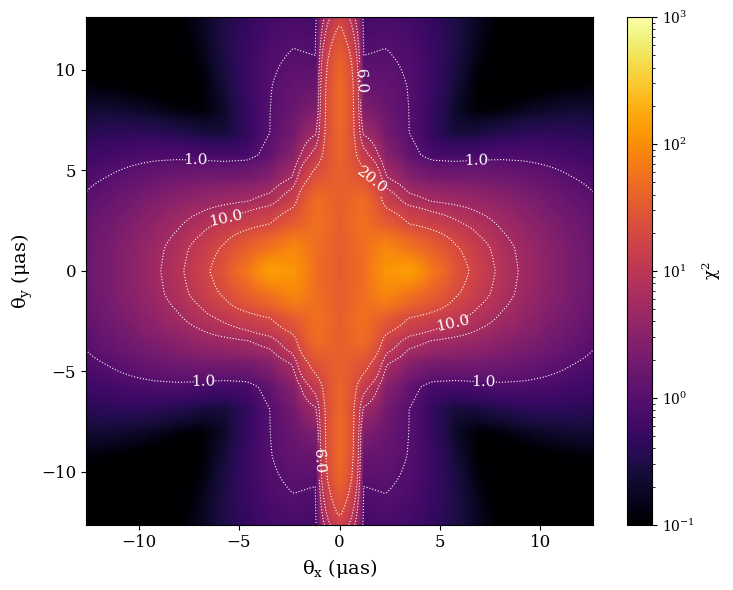

In [31]:
Z = np.flipud(chi_interp).T
X, Y = np.meshgrid(fine_grid_x*rad_to_arcsec, fine_grid_y*rad_to_arcsec)
#extent = [np.min(fine_grid_x), np.max(fine_grid_x), np.min(fine_grid_y), np.max(fine_grid_y)]
extent = np.array([np.min(fine_grid_x), np.max(fine_grid_x),  np.min(fine_grid_y), np.max(fine_grid_y)])*rad_to_arcsec    

levels=[1, 6, 10, 20]
# Mask values > 6
#masked_Z = np.ma.masked_where(Z > 6, Z)

fig, ax = plt.subplots(figsize=(12, 6))

im = ax.imshow(Z, origin='lower', extent=extent, cmap='inferno', norm=matplotlib.colors.LogNorm(vmin=.1,vmax=1000),)
contours = ax.contour(X, Y, Z, levels=levels, colors='white', linewidths=0.8, linestyles='dotted')
ax.clabel(contours, inline=True, fontsize=11, fmt="%.1f")

# Grey overlay for chi > 6 (where macrolensing wins)
#grey_mask = np.ma.masked_where(Z > 6, Z)
#ax.imshow(grey_mask, origin='lower', extent=extent, cmap='Greys', alpha=0.5, vmin=0, vmax=0)  # semi-transparent
cbar = plt.colorbar(im, ax=ax, fraction=0.045, pad=.03)
cbar.set_label(r'$\chi^2$', fontsize=12)

ax.tick_params(axis='both', which='major', labelsize=12)
ax.tick_params(axis='both', which='minor', labelsize=10)

ax.set_xlabel(r'$\theta_x \ (\mu as)$', fontsize=14)
ax.set_ylabel(r'$\theta_y \ (\mu as)$', fontsize=14)
plt.tight_layout()


plt.savefig('Figures/chi04.pdf', bbox_inches='tight')
FileLink('Figures/chi04.pdf')

### Error Plots

In [59]:
orig_map=plt.cm.get_cmap('cividis')

# reversing the original colormap using reversed() function
reversed_map = orig_map.reversed()

bulk_vel=400
bulk_vel_err=100
vel_disp=178
vel_disp_err=35

dist_x = get_velocities(np.array([0, np.sqrt(bulk_vel**2+vel_disp**2)*1e5]), B_matrix, z_l, D_l)
mu_x=np.sqrt(dist_x[0]**2+dist_x[1]**2)*356*24*3600*rad_to_arcsec

/tmp/ipykernel_1889883/4128783968.py:1: MatplotlibDeprecationWarning: The get_cmap function was deprecated in Matplotlib 3.7 and will be removed in 3.11. Use ``matplotlib.colormaps[name]`` or ``matplotlib.colormaps.get_cmap()`` or ``pyplot.get_cmap()`` instead.
  orig_map=plt.cm.get_cmap('cividis')


/mnt/home/amoran/lensing/M04/Figures/rad_04.pdf

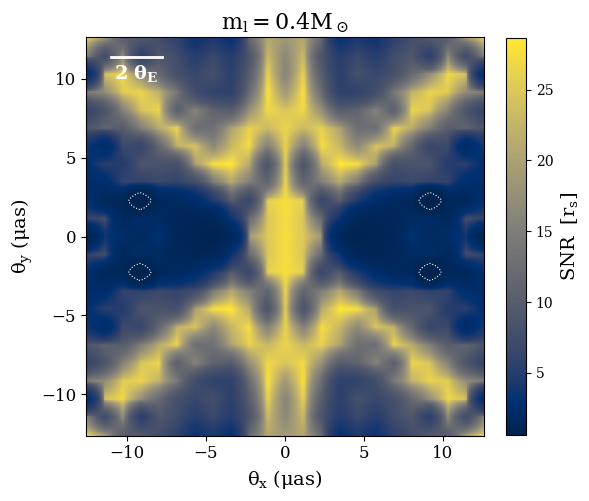

In [144]:
fig, (ax1) = plt.subplots(nrows=1, ncols=1, figsize=(6, 8))
extent = np.array([np.min(fine_grid_x), np.max(fine_grid_x),  np.min(fine_grid_y), np.max(fine_grid_y)])*rad_to_arcsec    
extent2 = [-theta_max, theta_max, -theta_max, theta_max]    #left right bottom top 

X, Y = np.meshgrid(fine_grid_x*rad_to_arcsec, fine_grid_y*rad_to_arcsec)
Z = rad_mas/np.flipud(rad_interp).T

levels=[.1, 1]
im=ax1.imshow(Z, origin='lower',  cmap=orig_map, extent=extent, )
              # norm=matplotlib.colors.LogNorm(vmin=.05, vmax=1),)#, vmax=1.3, vmin=.1)
cbar = plt.colorbar(im, ax=ax1, fraction=0.045)
cbar.set_label(r'SNR $\ [r_s]$', fontsize=14)

#contours
contours = ax1.contour(X, Y, Z, levels=levels, colors='white', linewidths=0.8, linestyles='dotted')
ax1.clabel(contours, inline=True, fontsize=10, fmt="%.1f")

#scale thing
scale_length = 2*theta_E_4*rad_to_arcsec    

# pick a position for the bar 
x_start = np.min(fine_grid_x) - 3.4 * scale_length
x_end = x_start + scale_length
y_pos = np.max(fine_grid_y*rad_to_arcsec)  + .1 *np.min(fine_grid_y*rad_to_arcsec)
ax1.plot([x_start, x_end], [y_pos, y_pos], color='white', lw=2)
ax1.text((x_start + x_end) / 2, y_pos * .85, r"$ 2 \ \theta_{E}$", color='white', ha='center', va='bottom', fontsize=14,
         fontweight='black')#, backgroundcolor='white')


ax1.tick_params(axis='both', which='major', labelsize=12)
ax1.tick_params(axis='both', which='minor', labelsize=10)
plt.title(r'$m_l=0.4M_\odot$', fontsize=16)
#ax1.set_xlim(-1.4e-11, .1e-11)
#ax1.set_ylim(-.1e-11, 1.4e-11)


ax1.set_xlabel(r'$\theta_x \ (\mu as)$', fontsize=14)
ax1.set_ylabel(r'$\theta_y \ (\mu as)$', fontsize=14)
plt.tight_layout()

plt.savefig('Figures/rad_04.pdf', bbox_inches='tight')
FileLink('Figures/rad_04.pdf')

/mnt/home/amoran/lensing/M04/Figures/mass_04.pdf

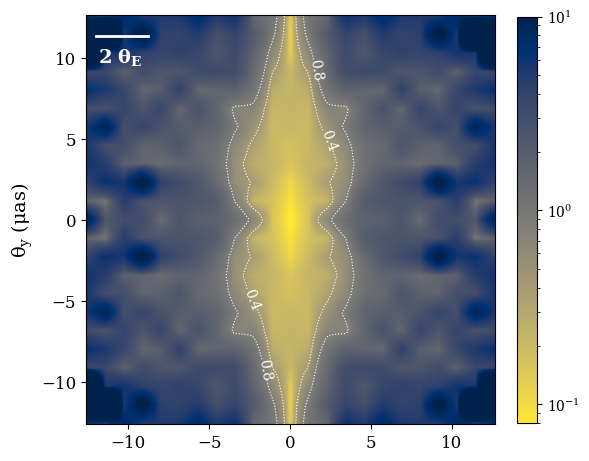

In [147]:
fig, (ax1) = plt.subplots(nrows=1, ncols=1, figsize=(6, 8))
extent = np.array([np.min(fine_grid_x), np.max(fine_grid_x),  np.min(fine_grid_y), np.max(fine_grid_y)])*rad_to_arcsec    
extent2 = [-theta_max, theta_max, -theta_max, theta_max]    #left right bottom top 

X, Y = np.meshgrid(fine_grid_x*rad_to_arcsec, fine_grid_y*rad_to_arcsec)
Z = np.flipud(mass_interp).T

levels=[ .4, .8]
im=ax1.imshow(np.flipud(mass_interp).T, origin='lower', cmap=reversed_map, norm=matplotlib.colors.LogNorm(vmin=8e-2,vmax=10), extent=extent)
cbar = plt.colorbar(im, ax=ax1, fraction=0.045)
#cbar.set_label(r'$ \sigma \ [m_l]\  (M_\odot)$', fontsize=14)

#contours
scale_length = 2*theta_E_4*rad_to_arcsec    

contours = ax1.contour(X, Y, Z, levels=levels, colors='white', linewidths=0.8, linestyles='dotted')
ax1.clabel(contours, inline=True, fontsize=10, fmt="%.1f")
x_start = np.min(fine_grid_x) - 3.7 * scale_length
x_end = x_start + scale_length
y_pos = np.max(fine_grid_y*rad_to_arcsec)  + .1 *np.min(fine_grid_y*rad_to_arcsec)
ax1.plot([x_start, x_end], [y_pos, y_pos], color='white', lw=2)
ax1.text((x_start-.3 + x_end) / 2, y_pos * .83, r"$ 2 \ \theta_{E}$", color='white', ha='center', va='bottom', fontsize=14,
         fontweight='black')#, backgroundcolor='white')


ax1.tick_params(axis='both', which='major', labelsize=12)
ax1.tick_params(axis='both', which='minor', labelsize=10)
#plt.title(r'$m_l=0.8M_\odot$', fontsize=16)
#ax1.set_xlim(-1.4e-11, .1e-11)
#ax1.set_ylim(-.1e-11, 1.4e-11)


#ax1.set_xlabel(r'$\theta_x \ (\mu as)$', fontsize=14)
ax1.set_ylabel(r'$\theta_y \ (\mu as)$', fontsize=14)
plt.tight_layout()


plt.savefig('Figures/mass_04.pdf', bbox_inches='tight')
FileLink('Figures/mass_04.pdf')

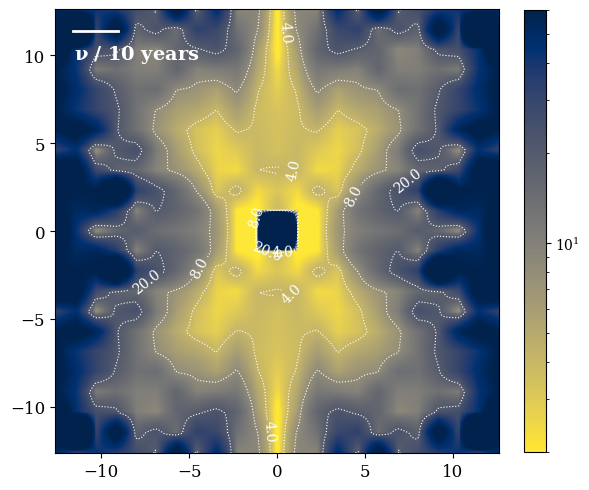

In [98]:
fig, (ax1) = plt.subplots(nrows=1, ncols=1, figsize=(6, 8))
extent = np.array([np.min(fine_grid_x), np.max(fine_grid_x),  np.min(fine_grid_y), np.max(fine_grid_y)])*rad_to_arcsec    

X, Y = np.meshgrid(fine_grid_x*rad_to_arcsec, fine_grid_y*rad_to_arcsec)
Z = np.sqrt(np.flipud(xpos_interp).T**2+np.flipud(xpos_interp).T**2)
levels=[4, 8, 20]
im=ax1.imshow(Z, origin='lower',cmap=reversed_map,norm=matplotlib.colors.LogNorm(vmin=2,vmax=60), extent=extent)
cbar = plt.colorbar(im, ax=ax1, fraction=0.045)
#cbar.set_label(r'$ \sigma \ [\theta_{\text{sep}}] \ (\mu as)$', fontsize=14)

#contours
contours = ax1.contour(X, Y, Z, levels=levels, colors='white', linewidths=0.8, linestyles='dotted')
ax1.clabel(contours, inline=True, fontsize=10, fmt="%.1f")

scale_length=mu_x*10
x_start = np.min(fine_grid_x) - 4.6* scale_length
x_end = x_start + scale_length
y_pos = np.max(fine_grid_y*rad_to_arcsec)  + .1 *np.min(fine_grid_y*rad_to_arcsec)
ax1.plot([x_start, x_end], [y_pos, y_pos], color='white', lw=2)
ax1.text(x_start+3.6, y_pos * .83, r"$\nu \ / $ 10 years", color='white', ha='center', va='bottom', fontsize=14,
         fontweight='black')#, backgroundcolor='white') # this is lensed along the x axis!!

ax1.tick_params(axis='both', which='major', labelsize=12)
ax1.tick_params(axis='both', which='minor', labelsize=10)
#ax1.set_xlim(-1.4e-11, .1e-11)
#ax1.set_ylim(-.1e-11, 1.4e-11)

#ax1.set_xlabel(r'$\theta_x \ (\mu as)$', fontsize=14)
#ax1.set_ylabel(r'$\theta_y \ (\mu as)$', fontsize=14)
plt.tight_layout()


plt.savefig('Figures/pos_04.pdf', bbox_inches='tight')
#FileLink('../Figures/pos_04.pdf')

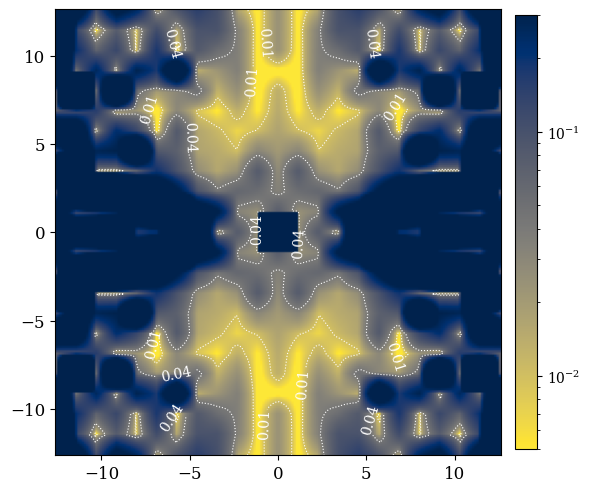

In [135]:
fig, (ax1) = plt.subplots(nrows=1, ncols=1, figsize=(6, 8))
extent = np.array([np.min(fine_grid_x), np.max(fine_grid_x),  np.min(fine_grid_y), np.max(fine_grid_y)])*rad_to_arcsec    

X, Y = np.meshgrid(fine_grid_x*rad_to_arcsec, fine_grid_y*rad_to_arcsec)
Z = np.flipud(sigma_c2_interp).T
levels=[.01, .04]
im=ax1.imshow(Z, origin='lower', cmap=reversed_map, extent=extent, norm=matplotlib.colors.LogNorm(vmin=.005,vmax=.3))#,  vmax=68, vmin=1)
cbar = plt.colorbar(im, ax=ax1, fraction=0.045, pad=.03)
#cbar.set_label(r'$ \sigma \ [|\theta_{\text{c}}|] \ (\mu as)$', fontsize=14)

#contours
contours = ax1.contour(X, Y, Z, levels=levels, colors='white', linewidths=0.8, linestyles='dotted')
ax1.clabel(contours, inline=True, fontsize=10, fmt="%.2f")

ax1.tick_params(axis='both', which='major', labelsize=12)
ax1.tick_params(axis='both', which='minor', labelsize=10)
#plt.title(r'$m_l=0.8M_\odot$', fontsize=16)
#ax1.set_xlim(-1.4e-11, .1e-11)
#ax1.set_ylim(-.1e-11, 1.4e-11)

#ax1.set_xlabel(r'$\theta_x \ (\mu as)$', fontsize=14)
#ax1.set_ylabel(r'$\theta_y \ (\mu as)$', fontsize=14)
plt.tight_layout()


plt.savefig('Figures/thetac2_04.pdf', bbox_inches='tight')


In [37]:
def Jcent_interp_batch(pos_array):
    # pos_array shape: (N, 2)
    N = pos_array.shape[0]
    J = np.empty((N, 2, 4))

    for a in range(2):
        for i in range(4):
            J[:, a, i] = interpolators_cent[a][i](pos_array)

    return J

In [71]:
# get some quantities on J_centroid that aren't based on matrix inversion to see if this is less noisy

Jall =Jcent_interp_batch(points)
Jc_sens = np.sqrt(np.sum(Jall**2, axis=(1,2))).reshape(sigma_c2_interp.shape)
colnorms = np.linalg.norm(Jall, axis=1)
Jc_col0_norm=colnorms[:,0].reshape(sigma_c2_interp.shape)
Jc_col1_norm=colnorms[:,1].reshape(sigma_c2_interp.shape)
Jc_col2_norm=colnorms[:,2].reshape(sigma_c2_interp.shape)
Jc_col3_norm=colnorms[:,3].reshape(sigma_c2_interp.shape)

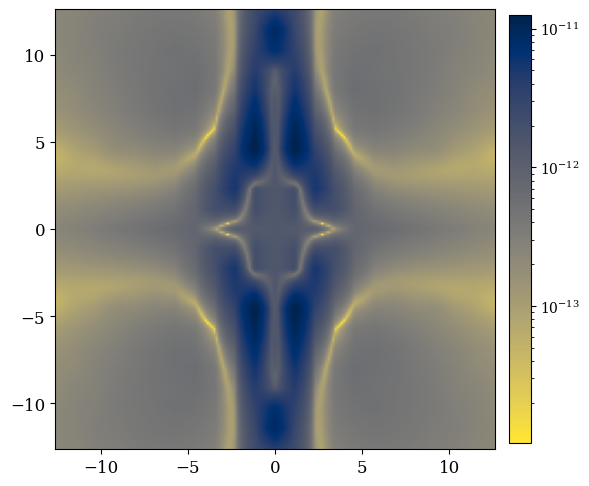

In [72]:
fig, (ax1) = plt.subplots(nrows=1, ncols=1, figsize=(6, 8))
extent = np.array([np.min(fine_grid_x), np.max(fine_grid_x),  np.min(fine_grid_y), np.max(fine_grid_y)])*rad_to_arcsec    

X, Y = np.meshgrid(fine_grid_x*rad_to_arcsec, fine_grid_y*rad_to_arcsec)
Z = np.flipud(Jc_col3_norm).T
im=ax1.imshow(Z, origin='lower', cmap=reversed_map, extent=extent, norm=matplotlib.colors.LogNorm())#,  vmax=68, vmin=1)
cbar = plt.colorbar(im, ax=ax1, fraction=0.045, pad=.03)

ax1.tick_params(axis='both', which='major', labelsize=12)
ax1.tick_params(axis='both', which='minor', labelsize=10)

plt.tight_layout()

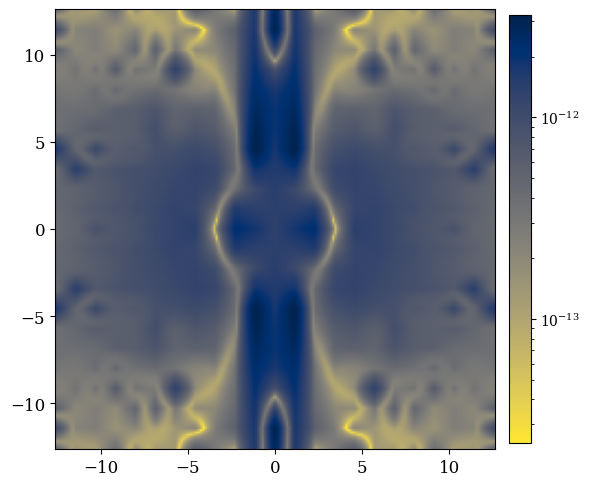

In [68]:
fig, (ax1) = plt.subplots(nrows=1, ncols=1, figsize=(6, 8))
extent = np.array([np.min(fine_grid_x), np.max(fine_grid_x),  np.min(fine_grid_y), np.max(fine_grid_y)])*rad_to_arcsec    

X, Y = np.meshgrid(fine_grid_x*rad_to_arcsec, fine_grid_y*rad_to_arcsec)
Z = np.flipud(Jc_col2_norm).T
im=ax1.imshow(Z, origin='lower', cmap=reversed_map, extent=extent, norm=matplotlib.colors.LogNorm())#,  vmax=68, vmin=1)
cbar = plt.colorbar(im, ax=ax1, fraction=0.045, pad=.03)

ax1.tick_params(axis='both', which='major', labelsize=12)
ax1.tick_params(axis='both', which='minor', labelsize=10)

plt.tight_layout()

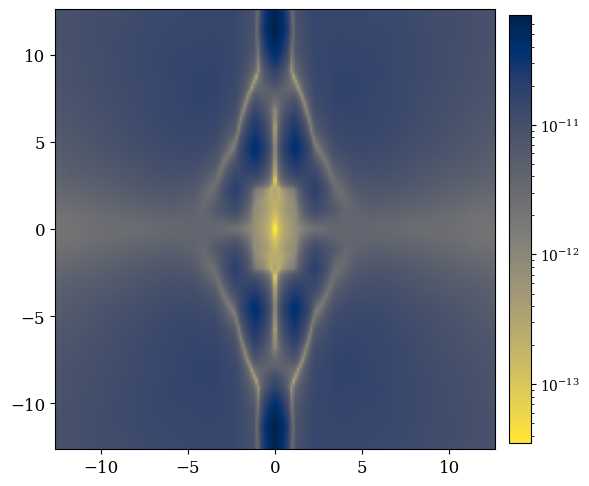

In [69]:
fig, (ax1) = plt.subplots(nrows=1, ncols=1, figsize=(6, 8))
extent = np.array([np.min(fine_grid_x), np.max(fine_grid_x),  np.min(fine_grid_y), np.max(fine_grid_y)])*rad_to_arcsec    

X, Y = np.meshgrid(fine_grid_x*rad_to_arcsec, fine_grid_y*rad_to_arcsec)
Z = np.flipud(Jc_col1_norm).T
im=ax1.imshow(Z, origin='lower', cmap=reversed_map, extent=extent, norm=matplotlib.colors.LogNorm())#,  vmax=68, vmin=1)
cbar = plt.colorbar(im, ax=ax1, fraction=0.045, pad=.03)

ax1.tick_params(axis='both', which='major', labelsize=12)
ax1.tick_params(axis='both', which='minor', labelsize=10)

plt.tight_layout()

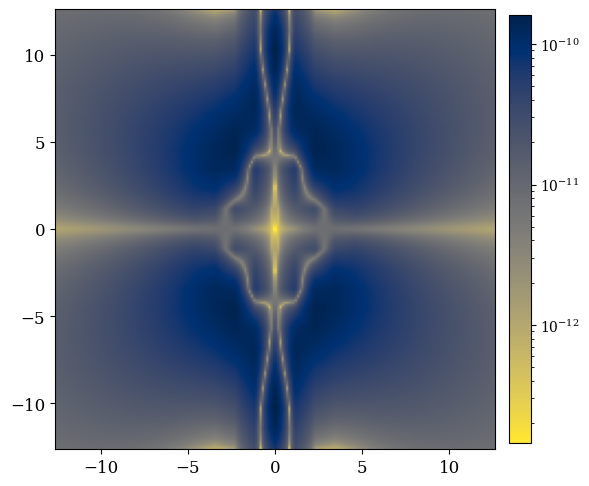

In [67]:
fig, (ax1) = plt.subplots(nrows=1, ncols=1, figsize=(6, 8))
extent = np.array([np.min(fine_grid_x), np.max(fine_grid_x),  np.min(fine_grid_y), np.max(fine_grid_y)])*rad_to_arcsec    

X, Y = np.meshgrid(fine_grid_x*rad_to_arcsec, fine_grid_y*rad_to_arcsec)
Z = np.flipud(Jc_col0_norm).T
im=ax1.imshow(Z, origin='lower', cmap=reversed_map, extent=extent, norm=matplotlib.colors.LogNorm())#,  vmax=68, vmin=1)
cbar = plt.colorbar(im, ax=ax1, fraction=0.045, pad=.03)

ax1.tick_params(axis='both', which='major', labelsize=12)
ax1.tick_params(axis='both', which='minor', labelsize=10)

plt.tight_layout()

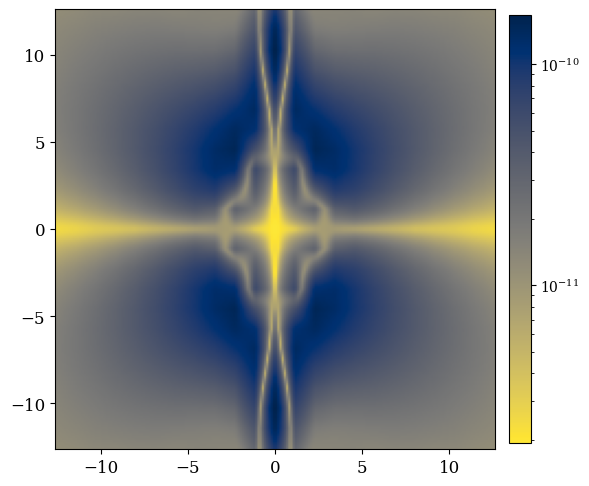

In [ ]:
fig, (ax1) = plt.subplots(nrows=1, ncols=1, figsize=(6, 8))
extent = np.array([np.min(fine_grid_x), np.max(fine_grid_x),  np.min(fine_grid_y), np.max(fine_grid_y)])*rad_to_arcsec    

X, Y = np.meshgrid(fine_grid_x*rad_to_arcsec, fine_grid_y*rad_to_arcsec)
Z = np.flipud(Jc_sens).T
im=ax1.imshow(Z, origin='lower', cmap=reversed_map, extent=extent, norm=matplotlib.colors.LogNorm())#,  vmax=68, vmin=1)
cbar = plt.colorbar(im, ax=ax1, fraction=0.045, pad=.03)

ax1.tick_params(axis='both', which='major', labelsize=12)
ax1.tick_params(axis='both', which='minor', labelsize=10)

plt.tight_layout()

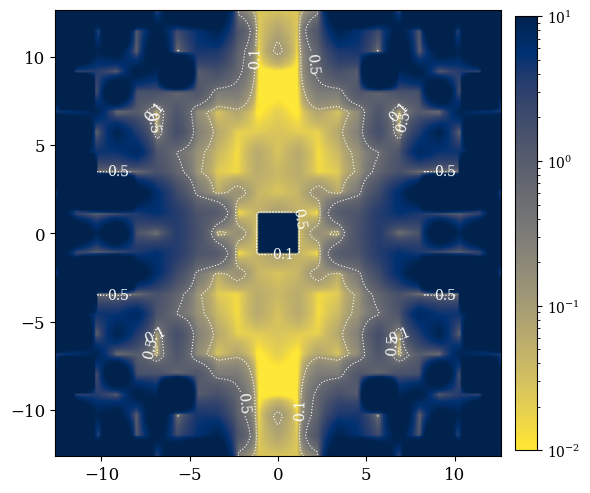

In [125]:
fig, (ax1) = plt.subplots(nrows=1, ncols=1, figsize=(6, 8))
extent = np.array([np.min(fine_grid_x), np.max(fine_grid_x),  np.min(fine_grid_y), np.max(fine_grid_y)])*rad_to_arcsec    

X, Y = np.meshgrid(fine_grid_x*rad_to_arcsec, fine_grid_y*rad_to_arcsec)
Z = np.flipud(sigma_c1_interp).T
levels=[.1, .5]
im=ax1.imshow(Z, origin='lower', cmap=reversed_map, extent=extent, norm=matplotlib.colors.LogNorm(vmin=.01,vmax=10))#,  vmax=68, vmin=1)
cbar = plt.colorbar(im, ax=ax1, fraction=0.045, pad=.03)
#cbar.set_label(r'$ \sigma \ [|\theta_{\text{c}}|] \ (\mu as)$', fontsize=14)

#contours
contours = ax1.contour(X, Y, Z, levels=levels, colors='white', linewidths=0.8, linestyles='dotted')
ax1.clabel(contours, inline=True, fontsize=10, fmt="%.1f")

ax1.tick_params(axis='both', which='major', labelsize=12)
ax1.tick_params(axis='both', which='minor', labelsize=10)
#plt.title(r'$m_l=0.8M_\odot$', fontsize=16)
#ax1.set_xlim(-1.4e-11, .1e-11)
#ax1.set_ylim(-.1e-11, 1.4e-11)

#ax1.set_xlabel(r'$\theta_x \ (\mu as)$', fontsize=14)
#ax1.set_ylabel(r'$\theta_y \ (\mu as)$', fontsize=14)
plt.tight_layout()


plt.savefig('Figures/thetac1_04.pdf', bbox_inches='tight')


### Simulating moving stars

In [29]:
def get_velocities(v_rest, B_matrix, redshift, lens_dist):
    """
    Inputs
        v_rest: velocity of the star in the lens plane in the same units at lens_dist/unit time
        redshift: redshift of lens (star)
        lens_dist: angular diameter distance to lens
        B_matrix: macrolensing matrix, inv_jacobian_fit
    Returns the lensed proper motion of the star in radians 
    """
    mu_rest = v_rest /(1 + redshift) * (1 / lens_dist) 
    mu_x = mu_rest[0] * B_matrix[0, 0] + mu_rest[1] * B_matrix[0, 1]
    mu_y = mu_rest[0] * B_matrix[1, 0] + mu_rest[1] * B_matrix[1, 1]
    return np.array((mu_x, mu_y))


def sim_rand_traj(bulk_vel, bulk_vel_err, vel_disp, vel_disp_err, theta_max, N, redshift, lens_dist, B_matrix, dist, 
                  dt_days=182.0, max_time_days= 5 * 365.0):
    """
    Simulate a single star trajectory in radians on an image grid
    Returns dict {'times_days', 'positions_rad' (radians Nx2), 'pixel_indices' (Nx2 ints), 'initial_position_rad', 'velocity_kms}

    Inputs:
        bulk_vel: km/s, asusmed to be entirely in the x direction (arb)
        bulk_vel_err: km/s
        vel_disp: km/s, velocity dispersion of the lensing galaxy
        theta_max: image smapens -theta_max to theta_max in x and y, radians
        N: number of pixels
        redshift: redshift of star
        lens_dist: in cm 
        B_matrix: inv_jacobian of the macrolensing stuff
        dt_days: cadence in days
        max_time_days: safety if we get a slow star     
    Returns:
        times_Deays: 1D array
        positions_rad: Nx2 array in rad
        pixel_indices: Nx2, ints, -1 for outside image
    The star passes at closest approach (impact parameter) = dist at t = 0.
    We integrate forward and backward in time with cadence dt_days.

    """

    km_to_cm = 1e5
    day_to_sec = 86400.0
    dt_sec = dt_days * day_to_sec
    max_time_sec = max_time_days * day_to_sec

    total_span = 2.0 * theta_max
    pixel_size = total_span / N

    # vel in km/s
    tot_vel=np.sqrt(bulk_vel**2+vel_disp**2)
    vel_angle=np.random.uniform(0, 2 * np.pi)
    
    v_x_kms =np.cos(vel_angle)*tot_vel #(np.random.normal(loc=bulk_vel, scale=bulk_vel_err)
               #+ np.random.normal(loc=0, scale=np.sqrt(vel_disp**2 + vel_disp_err**2)))
    v_y_kms = np.sin(vel_angle)*tot_vel#np.random.normal(loc=0, scale=np.sqrt(vel_disp**2 + vel_disp_err**2))

    # to angular
    v_rest = np.array([v_x_kms, v_y_kms]) * km_to_cm #to match lens_dist units
    v_ang = get_velocities(v_rest, B_matrix, redshift, lens_dist)
    v_x_ang, v_y_ang = v_ang

    v_norm = np.hypot(v_x_ang, v_y_ang)
    if v_norm == 0:
        raise ValueError("Zero velocity — cannot define trajectory direction.")

    # position at closest approach
    # direction perpendicular to velocity vector
    #phi = np.random.uniform(0, 2 * np.pi)  # pick random orientation of velocity
    # rotate velocity vector by angle phi around center to randomize orientation
    # rot = np.array([[np.cos(phi), -np.sin(phi)], [np.sin(phi), np.cos(phi)]])
    #v_ang_rot = rot @ np.array([v_x_ang, v_y_ang])
    #v_x_ang, v_y_ang = v_ang_rot

    # perpendicular unit vector
    n_perp = np.array([-v_y_ang, v_x_ang]) / np.hypot(v_x_ang, v_y_ang)
    theta0 = dist * n_perp  # position at closest approach
    theta_x0, theta_y0 = theta0
    times = np.arange(-max_time_sec, max_time_sec + dt_sec, dt_sec)

    theta_x = theta_x0 + v_x_ang * times
    theta_y = theta_y0 + v_y_ang * times
    positions = np.column_stack([theta_x, theta_y])
    pix_x = np.floor((theta_x + theta_max) / pixel_size).astype(int)
    pix_y = np.floor((theta_y + theta_max) / pixel_size).astype(int)
    
    inside = (pix_x >= 0) & (pix_x < N) & (pix_y >= 0) & (pix_y < N)
    
    """
    if not np.all(inside):
        first_out = np.argmax(~inside)   # first False
        # truncate arrays
        times = times[:first_out]
        theta_x = theta_x[:first_out]
        theta_y = theta_y[:first_out]
        pix_x = pix_x[:first_out]
        pix_y = pix_y[:first_out]
    """
    
    outside_mask = (pix_x < 0) | (pix_x >= N) | (pix_y < 0) | (pix_y >= N)
    pix_x[outside_mask] = -1
    pix_y[outside_mask] = -1
    pixel_indices = np.column_stack([pix_x, pix_y])

    times_days = times / day_to_sec

    return {"times_days": times_days, "positions_rad": positions, "pixel_indices": pixel_indices,
        "closest_approach_rad": (theta_x0, theta_y0), "velocity_kms": (v_x_kms, v_y_kms),
        "proper_motion": (v_x_ang, v_y_ang)} # rad/s


In [30]:
def plot_star_trajectory(traj, theta_max, show_start_end=True, ax=None):
    """
    Plot a single star trajectory
    
    show_start_end : bool, optional
        Mark starting and ending positions with scatter points
    ax : matplotlib.axes.Axes, optional
        Axes to plot on. If None, creates a new figure.
    """
    if ax is None:
        fig, ax = plt.subplots(figsize=(6, 6))

    theta_x, theta_y = traj["positions_rad"].T

    # Plot trajectory
    ls = '-'
    ax.plot(theta_x, theta_y, ls, color='C0', marker='.', linewidth=1.5)
    if show_start_end:
        ax.scatter(theta_x[0], theta_y[0], c='green', s=40, label='Start', zorder=3)
        ax.scatter(theta_x[-1], theta_y[-1], c='red', s=40, label='End', zorder=3)

    ax.set_xlim(-theta_max, theta_max)
    ax.set_ylim(-theta_max, theta_max)
    #pixel_size = 2 * theta_max / pixel_count
    #gridlines = np.linspace(-theta_max, theta_max, pixel_count + 1)
    #ax.set_xticks(gridlines[::max(1, pixel_count // 10)], minor=False)#, labelsize=12)
    #ax.set_yticks(gridlines[::max(1, pixel_count // 10)], minor=False)#, labelsize=12)
    ax.tick_params(axis='both', which='major', labelsize=12)

    ax.grid(True, linestyle='--', alpha=0.3)

    ax.set_xlabel(r'$\theta_x [\text{rad}]$', fontsize=15)
    ax.set_ylabel(r'$\theta_y [\text{rad}]$', fontsize=15)
    ax.set_aspect('equal', 'box')
    ax.legend(fontsize=14)
    return ax
# assume 400 km/s as in https://scixplorer.org/abs/2016ApJ...833..194W/abstract
# 178 km/s +/- 35 dispersion https://scixplorer.org/abs/2016A&A...590A..34W/abstract

In [31]:
bulk_vel=400
bulk_vel_err=100
vel_disp=178
vel_disp_err=35

test_traj=sim_rand_traj(bulk_vel, bulk_vel_err, vel_disp, vel_disp_err, np.max(x_grid), 8000, z_l, D_l, B_matrix, theta_E_1[0])

In [32]:
def f_alpha_to_f_Theta(f_alpha, times):
    """
    Convert f_alpha matrices (time-dependent) into a symmetric 6x6 f_Theta matrix
    inputs:
        f_alpha, shape (len(times), 4, 4)
        times: with t=0 at closest approach
    Returns f_theta, of shape 6,6
    """
    f_Theta = np.zeros((6, 6))

    for time, f_a in zip(times, f_alpha):
        # Upper 4x4 block
        f_Theta[:4, :4] += f_a

        # 5th row
        f_Theta[4, :4] += time * f_a[2, :]
        f_Theta[:4, 4] = f_Theta[4, :4]  # symmetry
        f_Theta[4, 4] += (time ** 2) * f_a[2, 2]

        # 6th row 
        f_Theta[5, :4] += time * f_a[3, :]
        f_Theta[:4, 5] = f_Theta[5, :4]  
        f_Theta[5, 4] += (time ** 2) * f_a[2, 3]
        f_Theta[4, 5] = f_Theta[5, 4]    
        f_Theta[5, 5] += (time ** 2) * f_a[3, 3]

    return f_Theta

In [27]:
positions_traj=test_traj['positions_rad']
fisher_alpha=[]
uncert_alphas=[]
for position_i in positions_traj:
    fisher_alpha.append(fisher_interp_linear(position_i))
    uncert_alphas.append(parameter_uncertainties(fisher_alpha[-1], theta_step, printout=False)[1])
uncert_alphas=np.array(uncert_alphas)

/tmp/ipykernel_1660852/41497333.py:14: DeprecationWarning: Conversion of an array with ndim > 0 to a scalar is deprecated, and will error in future. Ensure you extract a single element from your array before performing this operation. (Deprecated NumPy 1.25.)
  M[i, j] = interpolators[i][j]([x, y])


In [28]:
f_Theta = f_alpha_to_f_Theta(fisher_alpha, test_traj['times_days']*(3600*24))
cov_Theta, uncert_Theta = parameter_uncertainties(f_Theta, theta_step, printout=False, numstars=1)

### Now for many stars to get some averages

In [34]:
def centroid_acceleration_uncertainty(centroid_cov_traj, times_days):
    """
    Estimate uncertainty on centroid acceleration by fitting a quadratic
    model c(t) = c0 + v*t + 0.5*a*t^2 to the centroid trajectory.

    Parameters
    ----------
    centroid_cov_traj : array, shape (N, 2, 2)
        Centroid position covariance at each timestep (radians^2)
    times_days : array, shape (N,)
        Observation times in days

    Returns
    -------
    cov_acc : array, shape (2, 2)
        Covariance of centroid acceleration [a_x, a_y] (rad/s^2)^2
    sigma_acc : array, shape (2,)
        1-sigma uncertainty on acceleration in each sky direction
    """
    times_s = times_days * 86400.0
    F = np.zeros((6, 6))

    for i, t in enumerate(times_s):
        # Design matrix: maps [cx0, cy0, vx, vy, ax, ay] -> [cx(t), cy(t)]
        A_i = np.array([[1, 0, t, 0, t**2/2, 0],
            [0, 1, 0, t, 0,t**2/2]])  # shape (2, 6)
        C_inv = np.linalg.inv(centroid_cov_traj[i])
        F += A_i.T @ C_inv @ A_i

    cov_full = np.linalg.inv(F)         # full (6,6) covariance
    cov_acc  = cov_full[4:6, 4:6]      # acceleration block only
    sigma_acc = np.sqrt(np.diag(cov_acc))
    return cov_acc, sigma_acc

def unlens_sigma_from_cov(cov_Theta, B_matrix, redshift, lens_dist_cm):
    """
    Given the 6x6 Theta covariance, return the 1σ uncertainties
    on *unlensed* (physical) vx, vy in km/s.
    """
    cov_mu = cov_Theta[4:6, 4:6]   # 2x2 lensed angular-velocity covariance

    B_inv = np.linalg.inv(B_matrix)
    J = (1 + redshift) * lens_dist_cm * B_inv   # Jacobian

    cov_v_cm = J @ cov_mu @ J.T                 # cm^2/s^2
    cov_v_kms = cov_v_cm / (1e5**2)             # (km/s)^2

    sigma_v_kms = np.sqrt(np.diag(cov_v_kms))   
    return cov_v_cm, cov_v_kms, sigma_v_kms


def average_errors_traj(bulk_vel, bulk_vel_err, vel_disp, vel_disp_err, theta_max, N, redshift, lens_dist, B_matrix, dist, chi_spline,
                  dt_days=182.0, max_time_days= 5 * 365.0, n_its=100, fisher_spline=fisher_interp_linear):
    """
    Simulate random trajectories of a lensing system and compute average uncertainties and covariances for 
    trajectory parameters and centroid positions.

    Inputs:
    bulk_vel: float, lensing galaxy bulk vel in km/s
    bulk_vel_err: float, km/s
    vel_disp: float, vel dist of the stars in the lensing galaxy, km/s
    vel_disp_err: float, km/s
    theta_max: radians
    N: int, # of steps in each simulated trajectory
    redshift: float, source z
    lens_dist: float, lens distance (in same units as used in simulations)
    B_matrix: inv_jacobian of the macrolensing stuff
    dist: lens distance in cm 
    chi_spline , fisher_spline: callable default `fisher_interp_linear` for fisher_spline
    dt_days: float, optional. time step in days for trajectory simulation (default 182.0)
    max_time_days: float, optional, max total simulation time in days (default 5 years)
    n_its: int, optional, how many lenses to simulate motion for averaving    
    
    Outputs:
    cov_thetas: array: 6x6 cov matrixies for each lens trajectory
    cov_avg: average across trajectories
    uncert_thetas: array, len 6, uncertaintiy in theta space for each traj
    uncert_avg: average of that
    vels: the velocity we drew in each trajectory realization
    chi_all: array: total chi^2 values summed over each trajecotry
    retries: list of int, Number of retries needed for each trajectory to avoid NaNs in uncertainties.
    Jcents: array of 2x2 centroid covariance matricies combiend over each traj.
    """
    
    fisher_thetas=[]
    cov_thetas=[]
    uncert_thetas=[]
    vels=[]
    chi_all=[]
    retries=[]
    Jcents=[]
    acc_covs=[]
    acc_sigmas=[]
    for it in range(n_its):
        test_traj= sim_rand_traj(bulk_vel, bulk_vel_err, vel_disp, vel_disp_err, theta_max, N, redshift,
                                         lens_dist, B_matrix, dist,  dt_days=182.0, max_time_days= max_time_days)    
        positions_traj=test_traj['positions_rad']
        fisher_alpha=[]
        uncert_alphas=[]
        chi_traj=[]
        centJ_traj=[]
        vels.append(test_traj['velocity_kms'])
        for position_i in positions_traj:
            fisher_alpha.append(fisher_spline(position_i))
            uncert_alphas.append(parameter_uncertainties(fisher_alpha[-1], theta_step, printout=False)[1])
            chi_traj.append(chi_spline(position_i))
            centJ_traj.append(Jcent_interp(position_i))

            
        retry=0
        fisher_theta_traj=(f_alpha_to_f_Theta(fisher_alpha, test_traj['times_days']*(3600*24)))
        cov_Theta, uncert_Theta = parameter_uncertainties(fisher_theta_traj, theta_step, printout=False, numstars=1)
        while np.any(np.isnan(uncert_Theta)):
            retry += 1
            test_traj= sim_rand_traj(bulk_vel, bulk_vel_err, vel_disp, vel_disp_err, theta_max, N, redshift,
                                         lens_dist, B_matrix, dist,  dt_days=182.0, max_time_days= max_time_days)
            positions_traj=test_traj['positions_rad']
            fisher_alpha=[]
            uncert_alphas=[]
            chi_traj=[]
            Jcent_traj=[]
            vels.append(test_traj['velocity_kms'])
            for position_i in positions_traj:
                fisher_alpha.append(fisher_spline(position_i))
                uncert_alphas.append(parameter_uncertainties(fisher_alpha[-1], theta_step, printout=False)[1])
                chi_traj.append(chi_spline(position_i))
                Jcent_traj.append(Jcent_interp(position_i))
            fisher_theta_traj=(f_alpha_to_f_Theta(fisher_alpha, test_traj['times_days']*(3600*24)))
            cov_Theta, uncert_Theta = parameter_uncertainties(fisher_theta_traj, theta_step, printout=False, numstars=1)
        
        retries.append(retry)  
        centJ_traj=np.array(centJ_traj)
        centJ_traj = np.array([j.reshape(2,4) for j in centJ_traj])
        uncert_alphas=np.array(uncert_alphas)
        chi_all.append(np.sum(chi_traj))
        centroid_cov_traj = []

        for t in range(len(positions_traj)):
            J = centJ_traj[t]          # shape (2,4)
            C_alpha = np.linalg.inv(fisher_alpha[t])  # shape (4,4)
            C_cent = J @ C_alpha @ J.T    # shape (2,2)
            centroid_cov_traj.append(C_cent)
        

        centroid_cov_traj = np.array(centroid_cov_traj)
        cov_acc, sigma_acc = centroid_acceleration_uncertainty(centroid_cov_traj, test_traj['times_days'])
        acc_covs.append(cov_acc)
        acc_sigmas.append(sigma_acc)
        Cinv_tot = np.zeros((2, 2))
        
        for C in centroid_cov_traj: #combine timesteps into one, so invert, combine
            Cinv_tot += np.linalg.inv(C)
        
        C_cent_tot = np.linalg.inv(Cinv_tot) #invert back
        Jcents.append(C_cent_tot)
        fisher_thetas.append(f_alpha_to_f_Theta(fisher_alpha, test_traj['times_days']*(3600*24)))
        cov_v_cm, cov_v_kms, sigma_v_kms = unlens_sigma_from_cov(cov_Theta, B_matrix, redshift, lens_dist)
        cov_Theta, uncert_Theta = parameter_uncertainties(fisher_thetas[-1], theta_step, printout=False, numstars=1)
        cov_thetas.append(cov_Theta)
        uncert_unlensed = np.array(uncert_Theta.copy())
        
        # replace last two entries 
        _,_, sigma_v_kms = unlens_sigma_from_cov(cov_Theta, B_matrix, redshift, lens_dist)
        uncert_unlensed[4] = sigma_v_kms[0]*4.848136811e-12 # correct for mas to radians
        uncert_unlensed[5] = sigma_v_kms[1]*4.848136811e-12
        
        # store full 6-element uncertainty vector
        uncert_thetas.append(uncert_unlensed)
    cov_thetas=np.array(cov_thetas)
    Jcents=np.array(Jcents)
    chi_all=np.array(chi_all)#.reshape(len(chi_all))    
    cov_avg=np.mean(cov_thetas, axis=0)
    uncert_thetas=np.array(uncert_thetas)
    uncert_avg=np.sum(uncert_thetas, axis=0)/n_its
    vels=np.array(vels)
    return cov_thetas, cov_avg, uncert_thetas, uncert_avg, vels, chi_all, retries,  Jcents, acc_sigmas

In [96]:
cov_theta_all, cov_avg, uncert_theta_all, uncert_avg, vels, chi_traj, n_retry, J_cent=average_errors_traj(bulk_vel, bulk_vel_err, vel_disp, vel_disp_err, 
                                    np.max(x_grid), 8000, z_l, D_l, B_matrix, 5*theta_E_1[0], chi_spline, fisher_spline=fisher_interp_linear)

/tmp/ipykernel_1888932/3038925516.py:14: DeprecationWarning: Conversion of an array with ndim > 0 to a scalar is deprecated, and will error in future. Ensure you extract a single element from your array before performing this operation. (Deprecated NumPy 1.25.)
  M[i, j] = interpolators[i][j]([x, y])
/tmp/ipykernel_1888932/3547704378.py:17: DeprecationWarning: Conversion of an array with ndim > 0 to a scalar is deprecated, and will error in future. Ensure you extract a single element from your array before performing this operation. (Deprecated NumPy 1.25.)
  J[a, i] = interpolators_cent[a][i]([x, y])


### Uncertainties as a function of min impact parameter

In [35]:
from II_funcs import *

In [44]:
theta_E_8 = np.sqrt(4 * G * 0.8 * 2e33 / c**2 * D_ls / (D_s * D_l))
impact_params = np.linspace(0.3 * theta_E_8, 5.9 * theta_E_8, 40)[:30]

chi_tots, uncert_avgs, n_retries = [], [], []
chi_dists, uncert_dists = [], []
cent_all, acc_sigmas = [], []

for impact_param in impact_params:
    (cov_theta_all, cov_avg, uncert_theta_all, uncert_avg,
        vels, chi_traj_avg, n_r, cent_tot, acc_sigma) = average_errors_traj(bulk_vel, bulk_vel_err, vel_disp, vel_disp_err,
                                                    np.max(x_grid), 8000, z_l, D_l, B_matrix, impact_param, chi_spline,
                                                    fisher_spline=fisher_interp_linear, n_its=4000, max_time_days=2.5 * 365.0)

    chi_tots.append(chi_traj_avg.mean())
    uncert_avgs.append(uncert_avg)
    n_retries.append(n_r)
    chi_dists.append(chi_traj_avg)
    uncert_dists.append(uncert_theta_all)
    cent_all.append(cent_tot)
    acc_sigmas.append(acc_sigma)

results = {
    "impact_params": impact_params,
    "chi_tots": np.array(chi_tots),
    "cent_all": np.array(cent_all),
    "uncert_avgs": np.array(uncert_avgs),
    "n_retried": np.array(n_retries),
    "chi_dists": np.array(chi_dists, dtype=object),
    "uncert_dists": np.array(uncert_dists, dtype=object),
    "acc_sigmas": np.array(acc_sigmas, dtype=object),}

filename = "avgs_04_0417.npz"

try:
    existing = np.load(filename, allow_pickle=True)

    combined = {}
    for key, new_vals in results.items():
        old_vals = existing[key]

        if new_vals.ndim > 1 and key == "uncert_avgs":
            combined[key] = np.vstack([old_vals, new_vals])
        else:
            combined[key] = np.hstack([old_vals, new_vals])

except FileNotFoundError:
    combined = results

np.savez(filename, **combined)

/tmp/ipykernel_3514506/3038925516.py:14: DeprecationWarning: Conversion of an array with ndim > 0 to a scalar is deprecated, and will error in future. Ensure you extract a single element from your array before performing this operation. (Deprecated NumPy 1.25.)
  M[i, j] = interpolators[i][j]([x, y])
/tmp/ipykernel_3514506/3547704378.py:17: DeprecationWarning: Conversion of an array with ndim > 0 to a scalar is deprecated, and will error in future. Ensure you extract a single element from your array before performing this operation. (Deprecated NumPy 1.25.)
  J[a, i] = interpolators_cent[a][i]([x, y])


In [45]:
theta_E_8 = np.sqrt(4 * G * 0.8 * 2e33 / c**2 * D_ls / (D_s * D_l))
impact_params = np.linspace(0.3 * theta_E_8, 5.9 * theta_E_8, 40)[:30]

chi_tots, uncert_avgs, n_retries = [], [], []
chi_dists, uncert_dists = [], []
cent_all, acc_sigmas = [], []

for impact_param in impact_params:
    (cov_theta_all, cov_avg, uncert_theta_all, uncert_avg,
        vels, chi_traj_avg, n_r, cent_tot, acc_sigma) = average_errors_traj(bulk_vel, bulk_vel_err, vel_disp, vel_disp_err,
                                                    np.max(x_grid), 8000, z_l, D_l, B_matrix, impact_param, chi_spline,
                                                    fisher_spline=fisher_interp_linear, n_its=4000, max_time_days=2.5 * 365.0)

    chi_tots.append(chi_traj_avg.mean())
    uncert_avgs.append(uncert_avg)
    n_retries.append(n_r)
    chi_dists.append(chi_traj_avg)
    uncert_dists.append(uncert_theta_all)
    cent_all.append(cent_tot)
    acc_sigmas.append(acc_sigma)

results = {
    "impact_params": impact_params,
    "chi_tots": np.array(chi_tots),
    "cent_all": np.array(cent_all),
    "uncert_avgs": np.array(uncert_avgs),
    "n_retried": np.array(n_retries),
    "chi_dists": np.array(chi_dists, dtype=object),
    "uncert_dists": np.array(uncert_dists, dtype=object),
    "acc_sigmas": np.array(acc_sigmas, dtype=object),}

filename = "avgs_04_0417.npz"

try:
    existing = np.load(filename, allow_pickle=True)

    combined = {}
    for key, new_vals in results.items():
        old_vals = existing[key]

        if new_vals.ndim > 1 and key == "uncert_avgs":
            combined[key] = np.vstack([old_vals, new_vals])
        else:
            combined[key] = np.hstack([old_vals, new_vals])

except FileNotFoundError:
    combined = results

np.savez(filename, **combined)

/tmp/ipykernel_3514506/3038925516.py:14: DeprecationWarning: Conversion of an array with ndim > 0 to a scalar is deprecated, and will error in future. Ensure you extract a single element from your array before performing this operation. (Deprecated NumPy 1.25.)
  M[i, j] = interpolators[i][j]([x, y])
/tmp/ipykernel_3514506/3547704378.py:17: DeprecationWarning: Conversion of an array with ndim > 0 to a scalar is deprecated, and will error in future. Ensure you extract a single element from your array before performing this operation. (Deprecated NumPy 1.25.)
  J[a, i] = interpolators_cent[a][i]([x, y])


In [10]:
data = np.load("avgs_04_0417.npz", allow_pickle=True)

impact_params_all = data["impact_params"]
chi_all= data["chi_tots"]
uncert_all = data["uncert_avgs"]
chi_dists_all = data["chi_dists"]
uncert_dists_all = data["uncert_dists"] 

uniq = np.unique(impact_params_all)
chi_mean   = np.zeros(len(uniq))
uncert_mean = np.zeros((len(uniq), uncert_all.shape[1]))

for i, u in enumerate(uniq):
    mask = impact_params_all == u
    chi_mean[i]   = chi_all[mask].mean()
    uncert_mean[i] = uncert_all[mask].mean(axis=0)

impact_params = uniq
chi_full=np.array(chi_dists_all)
uncert_full=np.array(uncert_dists_all)

In [11]:
chi_dists_all.shape

(30, 11000)

In [12]:
# calcualte the percentiles for all this for plotting purposes
cent_all=data["cent_all"]
cent_precision1=np.linalg.det(cent_all)
cent_nans=np.copy(cent_all)
cent_nans[np.isnan(cent_all)]=0

cent_precision2=np.min(np.linalg.eigvals(cent_nans), axis=2)

sigma_cent1_mean = np.mean(cent_precision1, axis=-1)
sigma_cent2_mean = np.mean(cent_precision2, axis=-1)

sigma_cent1_84 = np.nanpercentile(cent_precision1, 84, axis=-1)
sigma_cent2_84 = np.nanpercentile(cent_precision2, 84, axis=-1)

sigma_cent1_16 = np.nanpercentile(cent_precision1, 16, axis=-1)
sigma_cent2_16 = np.nanpercentile(cent_precision2, 16, axis=-1)

sigma_cent1_50 = np.nanpercentile(cent_precision1, 50, axis=-1)
sigma_cent2_50 = np.nanpercentile(cent_precision2, 50, axis=-1)

In [22]:
acc_sigmas=data["acc_sigmas"]
acc_sigma_mean=np.mean(acc_sigmas, axis=-1)
acc_sigma_84 = np.nanpercentile(acc_sigma_mean, 84, axis=-1)
acc_sigma_16 = np.nanpercentile(acc_sigma_mean, 16, axis=-1)
acc_sigma_50 = np.nanpercentile(acc_sigma_mean, 50, axis=-1)


In [14]:
#check that all of these are in the area under chi^2=10, and they are!
n_retrys=data['n_retried']
cut=0
for i in range(len(n_retrys)):
    tries=np.sum(n_retrys[i])
    if tries>0:
        print("pos", np.array(impact_params/theta_E_8[0])[i], ':', tries)
    if np.percentile(chi_full, 50, axis=1)[i]<10 and cut==0:
        print('cutoff is ', np.array(impact_params/theta_E_8[0])[i])
        print('limit x axis to ', np.array(impact_params/theta_E_8[0])[i-1])
        xlim=np.array(impact_params/theta_E_8[0])[i-1]
        cut=10

cutoff is  3.7461538461538466
limit x axis to  3.6025641025641026


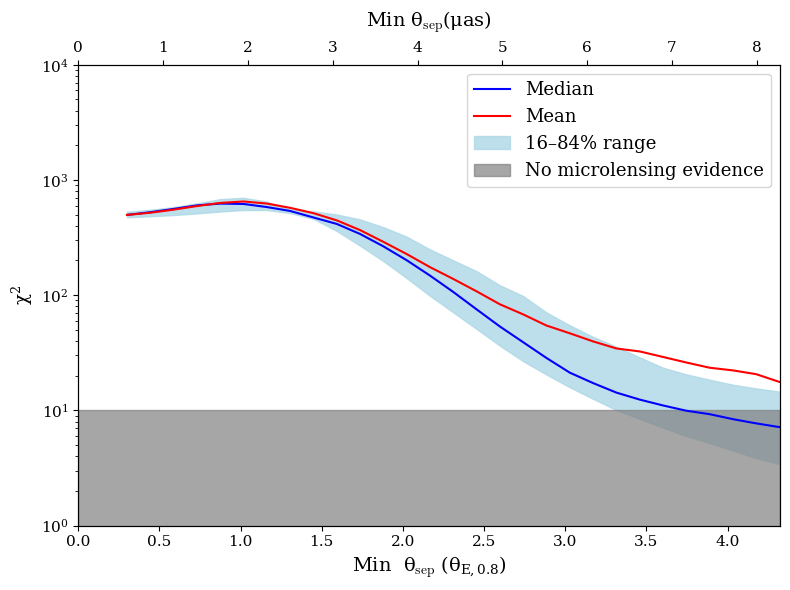

In [17]:
p16= np.array(np.percentile(chi_full, 16, axis=1), dtype=float)
p84 = np.array(np.percentile(chi_full, 84, axis=1), dtype=float)
xlim_real=xlim*1.2
fig,ax = plt.subplots(figsize=(8,6))

ax.plot(impact_params / theta_E_8, np.percentile(chi_full, 50, axis=1), color='blue', label='Median')
ax.plot(impact_params / theta_E_8, chi_mean, label='Mean', color='red')
ax.fill_between(impact_params / theta_E_8, p16, p84,  alpha=0.8, label='16–84% range', color='lightblue')

ax_top = ax.twiny() # for top axis
ax_top.spines["top"].set_position(("axes", 1))
ax_top.set_xlabel(r'Min $\theta_{\text{sep}}$($\mu$as)',  fontsize=14, labelpad=10)
ax_top.set_xlim(0,xlim*theta_E_8[0]*rad_to_arcsec)


ax_top.tick_params(axis='both', which='major', labelsize=11)
ax.tick_params(axis='both', which='major', labelsize=11)

ax.axhspan(0,10, label='No microlensing evidence', alpha=.7, color='gray')
ax.set_ylabel(r'$\chi^2$', fontsize=13)
ax.set_xlabel(r'Min  $\theta_{\text{sep}}$ ($\theta_{E, 0.8}$)', fontsize=14)
ax.set_yscale('log')
ax.set_xlim(0, xlim_real)
ax.set_ylim(1, 1e4)
ax.legend(fontsize=13)
fig.tight_layout() # 5 years
plt.savefig('Figures/chi_traj_04.pdf')

#### Uncertainties 

In [18]:
uncert_rads_avg =np.array(np.percentile(uncert_full[:,:,0], 50, axis=1))
uncert_mass_avg =np.array(np.percentile(uncert_full[:,:,1], 50, axis=1))
uncert_xpos_avg =np.array(np.percentile(uncert_full[:,:,2], 50, axis=1))
uncert_ypos_avg =np.array(np.percentile(uncert_full[:,:,3], 50, axis=1))
uncert_xvel_avg =np.array(np.percentile(uncert_full[:,:,4], 50, axis=1))
uncert_yvel_avg =np.array(np.percentile(uncert_full[:,:,5], 50, axis=1))

In [19]:
import pandas as pd

In [20]:
df=pd.DataFrame((np.array((impact_params/theta_E_8[0], uncert_rads_avg, uncert_mass_avg, 
                        uncert_xpos_avg, uncert_ypos_avg, uncert_xvel_avg, uncert_yvel_avg, sigma_cent1_50*rad_to_arcsec**4, sigma_cent2_50*rad_to_arcsec**2 )).T),
                        columns=['impact_param', 'uncert_rad', 'uncert_mass', 'uncert_xpos', 'uncert_ypos', 'uncert_xvel', 'uncert_yvel', 'cent_precision1', 'cent_precision2'])

df[['cent_precision1', 'cent_precision2']]

,cent_precision1,cent_precision2
0,0.000168,0.002795
1,0.000135,0.002506
2,0.000115,0.002258
3,0.000072,0.002049
4,0.000019,0.00185
5,0.000014,0.001818
6,0.000012,0.001925
7,0.000006,0.000844
8,0.000016,0.001183
9,0.000043,0.0016


In [26]:
xlim

np.float64(3.6025641025641026)

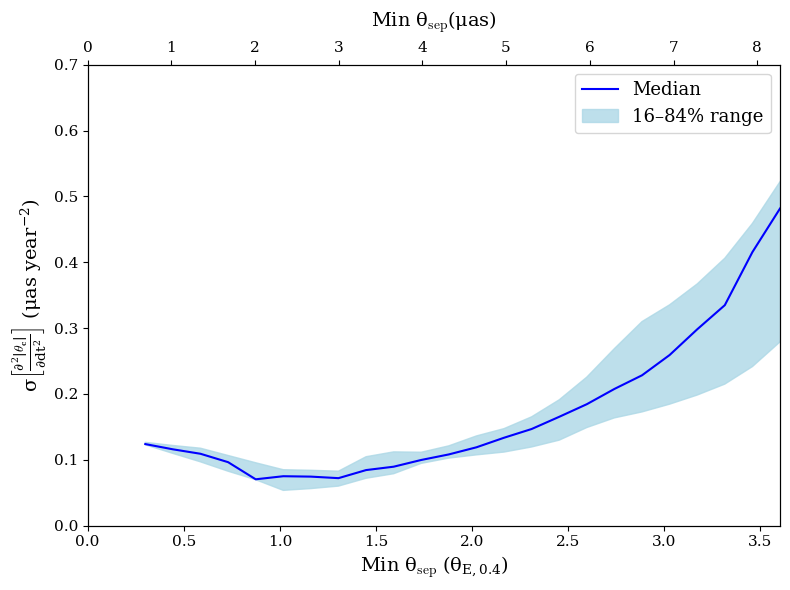

In [37]:
s_to_yr = 1 / (365.25 * 86400)  
p16 = acc_sigma_16* rad_to_arcsec / s_to_yr**2
p84= acc_sigma_84* rad_to_arcsec / s_to_yr**2

fig,ax = plt.subplots(figsize=(8,6))
ylim=.7
ax.plot(impact_params / theta_E_8, acc_sigma_50*rad_to_arcsec/s_to_yr**2, color='blue', label='Median')
ax.fill_between(impact_params / theta_E_8, p16, p84,  alpha=0.8, label='16–84% range', color='lightblue')

#ticks_top=np.linspace(theta_E_8[0]*rad_to_arcsec, np.round(xlim)*theta_E_8[0]*rad_to_arcsec, 6) 

ax_top = ax.twiny() # for top axis
ax_top.spines["top"].set_position(("axes", 1))
ax_top.set_xlabel(r'Min $\theta_{\text{sep}}$($\mu$as)',  fontsize=14, labelpad=10)
ax_top.set_xlim(0, xlim*theta_E_8[0]*rad_to_arcsec)

#ax_right.tick_params(axis='both', which='major', labelsize=11)
ax_top.tick_params(axis='both', which='major', labelsize=11)
ax.tick_params(axis='both', which='major', labelsize=11)

ax.set_xlabel(r'Min $\theta_{\text{sep}}$ ($\theta_{E, 0.4}$)', fontsize=14);
ax.set_ylabel(r"$\sigma \left[ \frac{\partial^2 |\mathbf{\theta_{c}}|}{\partial dt^2} \right]$ ($\mu$as year$^{-2}$)",  fontsize=14)
ax.set_xlim(0, xlim)
ax.set_ylim(0, ylim)

ax.legend(fontsize=13)
fig.tight_layout()

plt.savefig('Figures/thetac_acc_04.pdf')

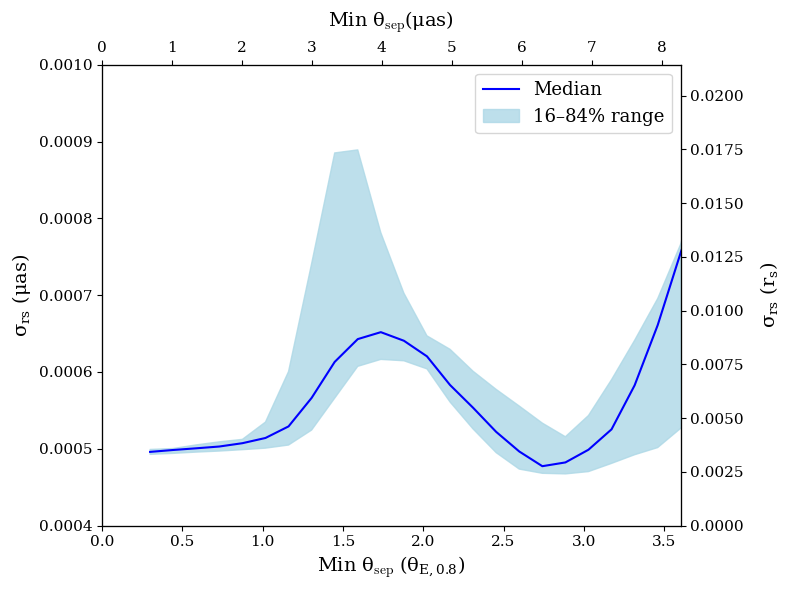

In [41]:
p16 = np.array(np.percentile(uncert_full[:,:,0], 16, axis=1), dtype=float)
p84= np.array(np.percentile(uncert_full[:,:,0], 84, axis=1), dtype=float)

fig,ax = plt.subplots(figsize=(8,6))
ylim=.001
ax.plot(impact_params / theta_E_8, np.percentile(uncert_full[:,:,0], 50, axis=1), color='blue', label='Median')
ax.fill_between(impact_params / theta_E_8, p16, p84,  alpha=0.8, label='16–84% range', color='lightblue')

ticks_top=np.linspace(theta_E_8[0]*rad_to_arcsec, 8*theta_E_8[0]*rad_to_arcsec, 6) 

ax_top = ax.twiny() # for top axis
ax_top.spines["top"].set_position(("axes", 1))
ax_top.set_xlabel(r'Min $\theta_{\text{sep}}$($\mu$as)',  fontsize=14, labelpad=10)
ax_top.set_xlim(0,xlim*theta_E_8[0]*rad_to_arcsec)

ax_right = ax.twinx() # for top axis
ax_right.spines["top"].set_position(("axes", 1))
ax_right.set_ylabel(r'$\sigma_{rs}$ ($r_s$)',  fontsize=14, labelpad=10)
ax_right.set_ylim(0,ylim/rad_mas)

ax_right.tick_params(axis='both', which='major', labelsize=11)
ax_top.tick_params(axis='both', which='major', labelsize=11)
ax.tick_params(axis='both', which='major', labelsize=11)

ax.set_xlabel(r'Min $\theta_{\text{sep}}$ ($\theta_{E, 0.8}$)', fontsize=14);
ax.set_ylabel(r"$\sigma_{rs}$ ($\mu$as)",  fontsize=14)
ax.set_xlim(0, xlim)
ax.set_ylim(.0004, ylim)

ax.legend(fontsize=13)
fig.tight_layout()
plt.savefig('Figures/rad_traj_04.pdf')

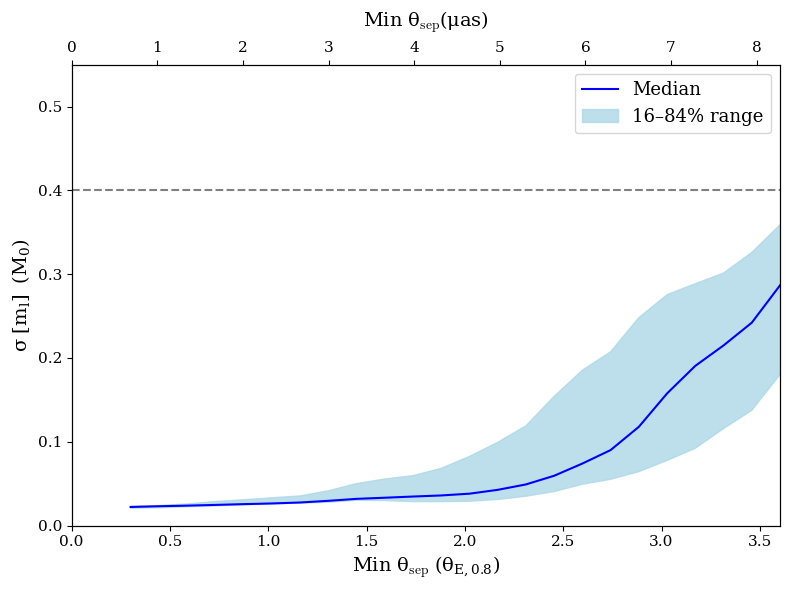

In [42]:
p16 = np.array(np.percentile(uncert_full[:,:,1], 16, axis=1), dtype=float)
p84 = np.array(np.percentile(uncert_full[:,:,1], 84, axis=1), dtype=float)

fig,ax = plt.subplots(figsize=(8,6))
ax.plot(impact_params / theta_E_8, np.percentile(uncert_full[:,:,1], 50, axis=1), color='blue', label='Median')
ax.fill_between(impact_params / theta_E_8, p16, p84,  alpha=0.8, label='16–84% range', color='lightblue')

ax_top = ax.twiny() # for top axis
ax_top.spines["top"].set_position(("axes", 1))
#ax_top.set_xticks(ticks_top, minor=False);
ax_top.set_xlabel(r'Min $\theta_{\text{sep}}$($\mu$as)',  fontsize=14, labelpad=10)
ax_top.set_xlim(0,xlim*theta_E_8[0]*rad_to_arcsec)
ax.axhline(0.4, linestyle='dashed', color='gray')


ax_top.tick_params(axis='both', which='major', labelsize=11)
ax.tick_params(axis='both', which='major', labelsize=11)

ax.set_xlabel(r'Min $\theta_{\text{sep}}$ ($\theta_{E, 0.8}$)', fontsize=14)
ax.set_ylabel(r"$\sigma \ [m_l]\ \ (M_0)$", fontsize=14)
ax.set_xlim(0, xlim)
ax.set_ylim(0, .55)
ax.legend(fontsize=13)
fig.tight_layout()
plt.savefig('Figures/mass_traj_04.pdf')

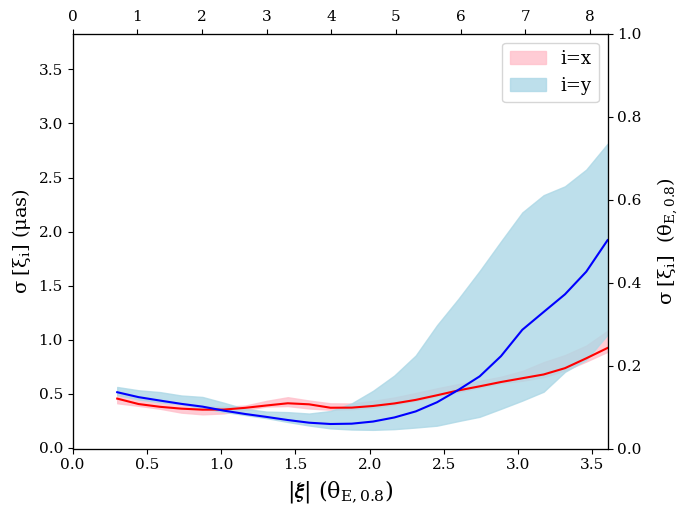

In [43]:
p16 = np.array(np.percentile(uncert_full[:,:,2], 16, axis=1), dtype=float)
p84= np.array(np.percentile(uncert_full[:,:,2], 84, axis=1), dtype=float)
fig,ax = plt.subplots(figsize=(7,5.25))

p16_y = np.array(np.percentile(uncert_full[:,:,3], 16, axis=1), dtype=float)
p84_y = np.array(np.percentile(uncert_full[:,:,3], 84, axis=1), dtype=float)

ax.plot(impact_params / theta_E_8, np.percentile(uncert_full[:,:,2], 50, axis=1), color='red')
ax.fill_between(impact_params / theta_E_8, p16, p84,  alpha=0.8, label='i=x', color='pink')

ax.plot(impact_params / theta_E_8, np.percentile(uncert_full[:,:,3], 50, axis=1), color='blue')
ax.fill_between(impact_params / theta_E_8, p16_y, p84_y,  alpha=0.8, label='i=y', color='lightblue')

ax_top = ax.twiny() # for top axis
ax_top.spines["top"].set_position(("axes", 1))
#ax_top.set_xticks(ticks_top, minor=False);
#ax_top.set_xlabel(r'Min $\theta_{\text{sep}}$($\mu$as)',  fontsize=14, labelpad=10)
ax_top.set_xlim(0,xlim*theta_E_8[0]*rad_to_arcsec)


ax_right = ax.twinx() # for top axis
ax_right.spines["top"].set_position(("axes", 1))
#ax_top.set_xticks(ticks_top, minor=False);
ax_right.set_ylabel(r'$\sigma \ [\xi_i]$  ($\theta_{E, 0.8}$)',  fontsize=14, labelpad=10)
#ax_right.set_ylim(0,ylim/(rad_to_arcsec*theta_E_8[0]))

ax_right.tick_params(axis='both', which='major', labelsize=11)
ax_top.tick_params(axis='both', which='major', labelsize=11)
ax.tick_params(axis='both', which='major', labelsize=11)

ax.set_xlabel(r'$|\boldsymbol{\xi}|$ ($\theta_{E, 0.8}$)', fontsize=16)
ax.set_ylabel(r"$\sigma \ [\xi_i]$ ($\mu$as)", fontsize=14)
ax.legend()
ax.set_xlim(0, xlim)
#ax.set_ylim(0, ylim)
ax.legend(fontsize=13)
fig.tight_layout()

plt.savefig('Figures/pos_traj_04.pdf', bbox_inches='tight')



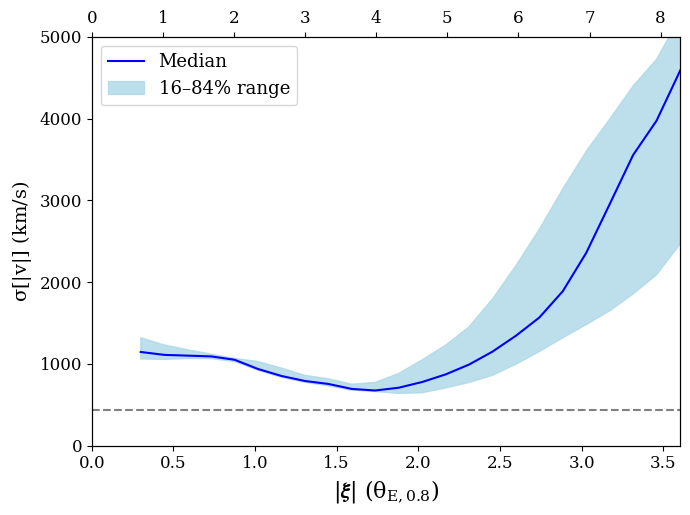

In [44]:
xvels=np.array(uncert_full[:,:,4])
yvels=np.array(uncert_full[:,:,5])
vels=np.array(xvels**2+yvels**2)**(.5)
p16 = (np.array(np.percentile(vels, 16, axis=1), dtype=float))
p84 =  (np.array(np.percentile(vels, 84, axis=1), dtype=float))
p50=(np.array(np.percentile(vels, 50, axis=1), dtype=float))
fig,ax = plt.subplots(figsize=(7,5.25))
ylim=5000


ax.plot(impact_params / theta_E_8, p50 , color='blue', label='Median')
ax.fill_between(impact_params / theta_E_8, p16, p84,  alpha=0.8, label='16–84% range', color='lightblue')

ax_top = ax.twiny() # for top axis
ax_top.spines["top"].set_position(("axes", 1))
#ax_top.set_xticks(ticks_top, minor=False);
#ax_top.set_xlabel(r'Min $\theta_{\text{sep}}$($\mu$as)',  fontsize=14, labelpad=10)
ax_top.set_xlim(0,xlim*theta_E_8[0]*rad_to_arcsec)

ax.axhline(np.sqrt(bulk_vel**2+vel_disp**2), linestyle='dashed', color='gray')

ax_top.tick_params(axis='both', which='major', labelsize=12)
ax.tick_params(axis='both', which='major', labelsize=12)

ax.set_xlabel(r'$|\boldsymbol{\xi}|$ ($\theta_{E, 0.8}$)', fontsize=16)
ax.set_ylabel(r"$\sigma [|v|]$ (km/s)", fontsize=14)
#plt.xlim(0.4, 2.5)
ax.set_xlim(0, xlim)
ax.set_ylim(0, ylim)
ax.legend(fontsize=13)
fig.tight_layout()

plt.savefig('Figures/vel_traj_04.pdf', bbox_inches='tight')


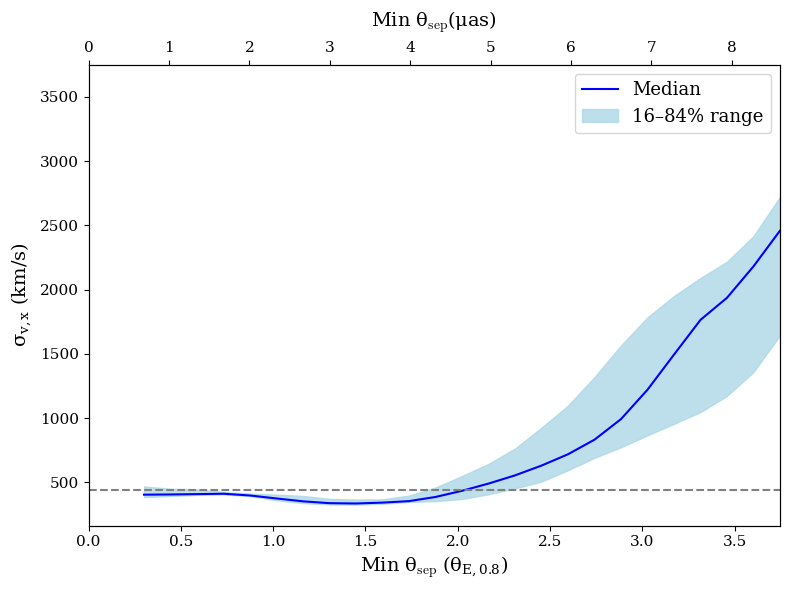

In [52]:
p16 = np.array(np.percentile(uncert_full[:,:,4], 16, axis=1), dtype=float)
p84 = np.array(np.percentile(uncert_full[:,:,4], 84, axis=1), dtype=float)

fig,ax = plt.subplots(figsize=(8,6)) #actual here has mean around 400 km/s and std 207.2 km/s
ylim=5.1

ax.plot(impact_params / theta_E_8, np.percentile(uncert_full[:,:,4], 50, axis=1),color='blue', label='Median')
ax.fill_between(impact_params / theta_E_8, p16, p84,  alpha=0.8, label='16–84% range', color='lightblue')

ax_top = ax.twiny() # for top axis
ax_top.spines["top"].set_position(("axes", 1))
#ax_top.set_xticks(ticks_top, minor=False);
ax_top.set_xlabel(r'Min $\theta_{\text{sep}}$($\mu$as)',  fontsize=14, labelpad=10)
ax_top.set_xlim(0,xlim*theta_E_8[0]*rad_to_arcsec)

ax.axhline(np.sqrt(bulk_vel**2+vel_disp**2), linestyle='dashed', color='gray')

ax_top.tick_params(axis='both', which='major', labelsize=11)
ax.tick_params(axis='both', which='major', labelsize=11)

ax.set_xlabel(r'Min $\theta_{\text{sep}}$ ($\theta_{E, 0.8}$)', fontsize=14)
ax.set_ylabel(r"$\sigma_{v, x}$ (km/s)", fontsize=14)
#plt.xlim(0.4, 2.5)
ax.set_xlim(0, xlim)
#ax.set_ylim(0, ylim)
ax.legend(fontsize=13)
fig.tight_layout()

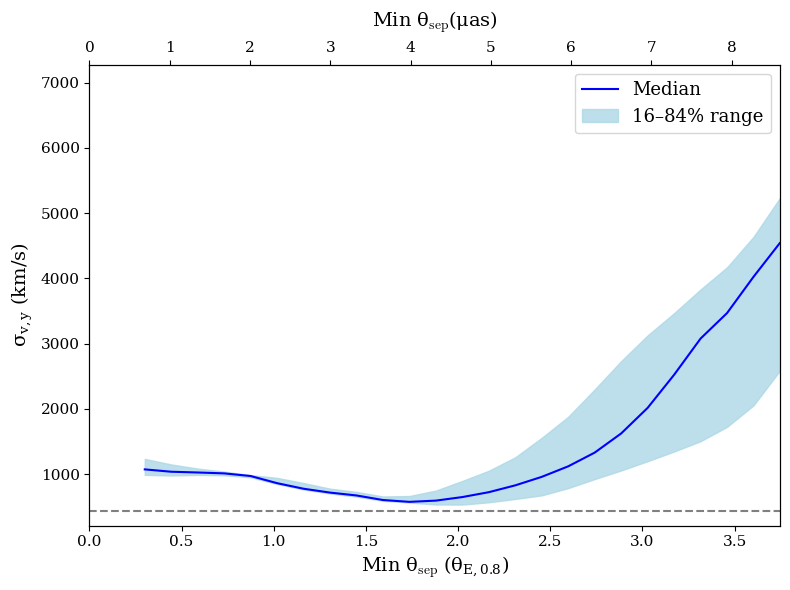

In [53]:
# mean 0 and std 181.4 km/s
p16 = np.array(np.percentile(uncert_full[:,:,5], 16, axis=1), dtype=float)
p84 = np.array(np.percentile(uncert_full[:,:,5], 84, axis=1), dtype=float)

fig,ax = plt.subplots(figsize=(8,6)) 
ylim=3.7

ax.plot(impact_params / theta_E_8, np.percentile(uncert_full[:,:,5], 50, axis=1), color='blue', label='Median')
ax.fill_between(impact_params / theta_E_8, p16, p84,  alpha=0.8, label='16–84% range', color='lightblue')
ax.axhline(np.sqrt(bulk_vel**2+vel_disp**2), linestyle='dashed', color='gray')

ax_top = ax.twiny() # for top axis
ax_top.spines["top"].set_position(("axes", 1))
#ax_top.set_xticks(ticks_top, minor=False);
ax_top.set_xlabel(r'Min $\theta_{\text{sep}}$($\mu$as)',  fontsize=14, labelpad=10)
ax_top.set_xlim(0,xlim*theta_E_8[0]*rad_to_arcsec)

ax_top.tick_params(axis='both', which='major', labelsize=11)
ax.tick_params(axis='both', which='major', labelsize=11)

ax.set_xlabel(r'Min $\theta_{\text{sep}}$ ($\theta_{E, 0.8}$)', fontsize=14)
ax.set_ylabel(r"$\sigma_{v, y}$ (km/s)", fontsize=14)
ax.set_xlim(0, xlim)
#ax.set_ylim(0, ylim)
ax.legend(fontsize=13)
fig.tight_layout()

In [ ]:
# 2/tau = 4 so we would expect a bit worse here 

### Probabilities

In [ ]:
def expected_time_to_encounter(stellar_density, v_bulk, v_bulk_err, vel_disp, vel_disp_err, L_min, 
                               B_matrix, redshift, lens_dist, n_samples=100000,seed=None, L_max=None):
    """
    get expected time for a star to come within L_min of the quasar, given surface density near the quasar and velocity distributions
    inputs:
        stellar_density: surface number density of stars (in 1/rad^2)
        v_bulk: vel of the galaxy in km/s, assuemd to be entirely in the x-direction
        vel_disp: km/s
        L_min: minimum impact distance, ie how close we require our star to be to the quasar
        n_samples: number of samples to estimate the avg transverse speed
    returns:
        t_exp_yr: time until the next close encounter in years
        encounter_rate: inverse of t_exp_yr, num encounters/yr
    """
    
    rng = np.random.default_rng(seed)
    seconds_year=31536000
    
    # angular => distances in cm
    L_min_phys = L_min * D_l
    if L_max is not None:
        L_max_phys = L_max * D_l
    else:
        L_max_phys = None

    # same vel as above 
    #==v_x = np.array((rng.normal(v_bulk, v_bulk_err, n_samples) + rng.normal(0, np.sqrt(vel_disp**2 + vel_disp_err**2), n_samples)))
    #==v_y = np.array(rng.normal(0, np.sqrt(vel_disp**2 + vel_disp_err**2), n_samples))
    velocities_cm = np.stack([v_x, v_y], axis=-1) * 1e5

    # get_velocities returns angular velocity (rad/s)
    v_ang = np.array([get_velocities(v, B_matrix, redshift, lens_dist) for v in velocities_cm])
    # convert back to cm/s
    v_phys = v_ang * lens_dist
    v_perp = np.sqrt(v_phys[:, 0]**2 + v_phys[:, 1]**2)
    
    # effective width of encounter band
    if L_max_phys is None:
        delta_L = L_min_phys  # encounter within radius L_min
    else:
        delta_L = (L_max_phys - L_min_phys)  # encounter between L_min and L_max

    # per-star area swept per second 
    rate_per_star = 2 * delta_L * v_perp
    encounter_rate = stellar_density * np.mean(rate_per_star)
    t_expected = 1.0 / encounter_rate
    t_exp_yr=t_expected/seconds_year
    char_time=delta_L/np.mean(v_perp)/seconds_year
    
    return t_exp_yr, 1/t_exp_yr, char_time


In [ ]:
# kappa values are here: https://arxiv.org/pdf/2303.11987
kappa_star= 0.04 #1.09 #dimensionless, we want this over kappa_crit
kappa_crit=(c**2/(4*np.pi*G))*(D_s/(D_l*D_ls)) # g/cm^2
Sigma_star=kappa_star*kappa_crit
avg_star_mass=.5*u.solMass.to(u.g)
n=(Sigma_star/avg_star_mass) #stars/cm^2
expected_time_to_encounter(n, bulk_vel, bulk_vel_err, vel_disp, vel_disp_err, theta_E_1[0], B_matrix, z_l, D_l, L_max=None)

In [ ]:
# this paper: https://arxiv.org/pdf/astro-ph/0511594 
# seems to give very different values for vmin and vmax, so im not sure what thats about